# Extended-phase-space integrators: Explicit (Pihajoki, Tao) and Semi-Explicit (Jayawardana-Ohsawa)

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Could not find the project root containing the src folder.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\USER\Desktop\hamiltonian-dynamics-benchmark


In [2]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from src.datasets.generate import generate_dataset
from src.datasets.systems.low_dim import (
    SimplePendulum, DoublePendulum, MassSpringSystem, HenonHeiles, FermiPastaUlamTsingou,
    SphericalPendulum, KeplerProblem, ChargedParticleMagneticTrap,
)

from src.datasets.systems.low_dim import CoupledOscillators
from src.datasets.integrators import midpoint, verlet
from src.integrators.explicit_extended_space import tao, pihajoki
from src.integrators import INTEGRATORS as EXT

warnings.filterwarnings("ignore")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "legend.fontsize": 8}
)

pd.set_option("display.float_format", "{:.3g}".format)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Configuration

In [ ]:
SYSTEM_BUILDERS = {
    "simple_pendulum": lambda: SimplePendulum(),
    "double_pendulum": lambda: DoublePendulum(),
    "mass_spring": lambda: MassSpringSystem(),
    "henon_heiles": lambda: HenonHeiles(),
    "coupled_oscillators": lambda: CoupledOscillators(n=3),
    "fput": lambda: FermiPastaUlamTsingou(m=3, omega=50.0),
    "kepler":             lambda: KeplerProblem(dim=2),
    "charged_particle":   lambda: ChargedParticleMagneticTrap(dim=2),
    "spherical_pendulum": lambda: SphericalPendulum(),
}
SYSTEMS = list(SYSTEM_BUILDERS)  

# Per-system settings
#   T, steps      : long run used for drift / error curves   (h = T / steps)
#   T_err         : horizon at which the state error is summarised
#                   (chaotic systems: keep it within a few Lyapunov times)
#   conv_T        : horizon of the convergence / stability sweep
#   roll_T/steps  : rollout used for the learned models 
#   separable     : H = T(p) + V(q)?  Verlet is only run when True
#   chaotic       : informational flag (drawn as a marker on the plots)
#   omega0        : characteristic frequency; Tao's omega = rel * omega0

_DEFAULT = dict(
    T=50.0, steps=1000, T_err=50.0, conv_T=10.0,
    roll_T=15.0, roll_steps=300,
    separable=True, chaotic=False, omega0=1.0,
)

SYSTEM_CFG = {k: dict(_DEFAULT) for k in SYSTEM_BUILDERS}
SYSTEM_CFG["double_pendulum"].update(
    T=20.0, steps=2000, T_err=5.0, conv_T=5.0,
    roll_T=5.0, roll_steps=250, separable=False, chaotic=True,
)

# Henon-Heiles is chaotic only at high enough energy; adjust to initial conditions
SYSTEM_CFG["henon_heiles"].update(
    T_err=20.0, conv_T=5.0, chaotic=True,
)

SYSTEM_CFG["fput"] = dict(_DEFAULT)
SYSTEM_CFG["fput"].update(T=10.0, steps=2000, T_err=10.0, conv_T=1.0,
                          separable=True, chaotic=False, omega0=5.0)

SYSTEM_CFG["kepler"].update(T=50.0, steps=1000, T_err=50.0, conv_T=10.0,
                            separable=True, omega0=2.0)

SYSTEM_CFG["charged_particle"].update(T=30.0, steps=1500, T_err=30.0, conv_T=5.0,
                                      separable=False, omega0=2.0, reversible=False)

SYSTEM_CFG["spherical_pendulum"].update(T=30.0, steps=1500, T_err=30.0, conv_T=5.0,
                                        separable=False, omega0=1.0, roll_steps=600)

# ----------------------------------------------------------------------------
# True Dynamics part settings
# ----------------------------------------------------------------------------
N_TEST, SEED_TEST = 8, 123              # test trajectories per system (metrics: median over them)
CONV_STEPS = [5, 10, 20, 40, 80, 160, 320]  # step counts of the convergence / stability sweep (h = conv_T / n)
STAB_TOL = 0.5                          # "stable" = max drift < STAB_TOL * (1 + |H0|)
TAO_OMEGA_REL = 10.0                    # Tao omega used in the main comparison (x omega0)
OMEGAS_REL = [0.0, 1.0, 10.0, 100.0]    # Tao restraint sweep (x omega0)
FOCUS_SYSTEM = "double_pendulum"                 
POINCARE_T, POINCARE_STEPS, POINCARE_N = 400.0, 8000, 4

# ----------------------------------------------------------------------------
# Learned models part settings
# ----------------------------------------------------------------------------
RUN_LEARNED = True
LEARNED_SYSTEMS = ["double_pendulum", "henon_heiles", "spherical_pendulum"]
MODELS = ["HNN", "GeoHNN"]
TRAIN_SEEDS = [42, 43]                  # one dataset + one init per seed
N_TRAIN, TSPAN_TRAIN, STEPS_TRAIN = 30, (0.0, 10.0), 500
HIDDEN, EPOCHS, BATCH, LR = 64, 40, 256, 1e-3
REF_RTOL, REF_ATOL = 1e-6, 1e-8         # tight reference solve of the learned field
FOCUS_MODEL = "GeoHNN"

RUN_ABLATION = True                     # focus system + focus model only
ABL_NTRAIN = [5, 30]
ABL_NOISE = [0.0, 0.05]                 # relative to the std of each state dimension

# ----------------------------------------------------------------------------
# Output
# ----------------------------------------------------------------------------
OUT = ROOT / "outputs" / "extended_phase_space"
OUT.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Methods: label -> (solver name, omega)
# ----------------------------------------------------------------------------
def methods_for(key, verlet=True):
    cfg = SYSTEM_CFG[key]
    m = {
        "Pihajoki": ("pihajoki", None),
        "Tao (order 2)": ("tao", TAO_OMEGA_REL * cfg["omega0"]),
        "Tao (order 4)": ("tao4", TAO_OMEGA_REL * cfg["omega0"]),
        "J-O (order 2)": ("jayawardana_ohsawa", None),
        "J-O (order 4)": ("jayawardana_ohsawa4", None),
        "Midpoint": ("midpoint", None),
        "RK4": ("rk4", None),
    }
    if verlet and cfg["separable"]:
        m["Verlet"] = ("verlet", None)
    return m


ALL_LABELS = list(dict.fromkeys(l for k in SYSTEMS for l in methods_for(k)))
BASELINES = {"Midpoint", "RK4", "Verlet"}
COLORS = {
    "Pihajoki": "tab:orange",
    "Tao (order 2)": "tab:blue",
    "Tao (order 4)": "tab:pink",
    "J-O (order 2)": "tab:cyan",
    "J-O (order 4)": "tab:brown",
    "Midpoint": "tab:green",
    "RK4": "tab:red",
    "Verlet": "tab:purple",
}

def sty(label):
    return dict(color=COLORS.get(label), ls="--" if label in BASELINES else "-", lw=1.5)

## Helpers

In [4]:
# ----------------------------------------------------------------------------
# Flat batched representation: N trajectories -> [q_all, p_all]
# ----------------------------------------------------------------------------
def stack(Y, d):
    # (N, 2d) -> flat [q_all, p_all]
    Y = np.asarray(Y, float)
    return np.concatenate([Y[:, :d].ravel(), Y[:, d:].ravel()])


def unstack(flat_traj, N, d):
    # (T, 2Nd) -> (N, T, 2d)
    q = flat_traj[:, : N * d].reshape(-1, N, d)
    p = flat_traj[:, N * d :].reshape(-1, N, d)
    return np.concatenate([q, p], axis=2).transpose(1, 0, 2)


def oracle_field_batched(system, N, d):
    # true dynamics for N trajectories stacked as one big system
    def f(t, flat):
        q = flat[: N * d].reshape(N, d)
        p = flat[N * d :].reshape(N, d)
        out = np.empty((N, 2 * d))
        for i in range(N):
            out[i] = system.dynamics(t, np.concatenate([q[i], p[i]]))
        return np.concatenate([out[:, :d].ravel(), out[:, d:].ravel()])

    return f


def solve_reference(f_flat, Y0, d, T, n, rtol, atol, fallbacks=((1e-8, 1e-8),)):
    # tight DOP853 solve on the same time grid -> (N, n+1, 2d); loosen tolerances if it fails
    last = None
    for rt, at in ((rtol, atol), *fallbacks):
        sol = solve_ivp(
            f_flat, (0.0, T), stack(Y0, d), method="DOP853",
            t_eval=np.linspace(0.0, T, n + 1), rtol=rt, atol=at,
        )
        if sol.success:
            return unstack(sol.y.T, len(Y0), d)
        last = sol.message
    raise RuntimeError(last)


class Counted:
    # counts field evaluations (weight = number of trajectories one call evaluates)
    def __init__(self, f, weight=1):
        self.f, self.w, self.n = f, weight, 0

    def __call__(self, t, y):
        self.n += self.w
        return self.f(t, y)


def rk4(f, tspan, y0, n):
    h = (tspan[1] - tspan[0]) / n
    y = np.asarray(y0, float).copy()
    t = tspan[0]
    out = np.empty((n + 1, y.size))
    out[0] = y
    for i in range(n):
        k1 = f(t, y)
        k2 = f(t + h / 2, y + h / 2 * k1)
        k3 = f(t + h / 2, y + h / 2 * k2)
        k4 = f(t + h, y + h * k3)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        t += h
        out[i + 1] = y
    return tspan[0] + h * np.arange(n + 1), out


SINGLE = {"midpoint": midpoint, "verlet": verlet}  # run one trajectory at a time
BATCHED = {
    "rk4": rk4,
    "pihajoki": pihajoki,
    "jayawardana_ohsawa": EXT["jayawardana_ohsawa"],
    "jayawardana_ohsawa4": EXT["jayawardana_ohsawa4"],
}


def run_method(name, omega, Y0, d, T, n, f_flat, f_single):
    # -> dict(traj=(N, n+1, 2d), seconds, evals = field evaluations per trajectory-step)
    Y0 = np.asarray(Y0, float)
    N = len(Y0)
    t0 = time.perf_counter()
    try:
        if name in SINGLE:
            cs = Counted(f_single)
            traj = np.stack(
                [SINGLE[name](cs, (0.0, T), y0, n)[1] for y0 in Y0]
            )
            evals = cs.n
        else:
            cf = Counted(f_flat, weight=N)
            flat0 = stack(Y0, d)
            if name in ("tao", "tao4"):
                _, y = tao(cf, (0.0, T), flat0, n, omega=omega, order=4 if name == "tao4" else 2)
            else:
                _, y = BATCHED[name](cf, (0.0, T), flat0, n)
            traj, evals = unstack(y, N, d), cf.n
        return dict(traj=traj, seconds=time.perf_counter() - t0, evals=evals / (N * n))
    except Exception as e:
        print(f"   [{name}] failed: {type(e).__name__}: {e}")
        return dict(traj=None, seconds=np.nan, evals=np.nan)


def run_all(methods, *args):
    return {
        label: run_method(name, omega, *args)
        for label, (name, omega) in methods.items()
    }

In [5]:
# ----------------------------------------------------------------------------
# Metrics. Per-trajectory arrays have shape (N, T); scalars are medians over trajectories.
# ----------------------------------------------------------------------------
def _clean(A):
    A = np.asarray(A, float)
    return np.where(np.isfinite(A), A, np.inf)


def state_error(traj, ref):
    with np.errstate(all="ignore"):
        return np.linalg.norm(traj - ref, axis=2)  # (N, T)


def energy_drift(H_fn, traj):
    # H_fn maps (M, 2d) -> (M,)
    N, T, D = traj.shape
    with np.errstate(all="ignore"):
        H = H_fn(traj.reshape(-1, D)).reshape(N, T)
        return np.abs(H - H[:, :1])  # (N, T)


def true_H_fn(system):
    return lambda X: np.array([float(system.hamiltonian(s)) for s in X])


def err_at(A, i):
    return float(np.median(_clean(A)[:, i]))


def mean_over_time(A):
    with np.errstate(all="ignore"):
        return float(np.median(_clean(A).mean(axis=1)))


def max_over_time(A):
    return float(np.median(_clean(A).max(axis=1)))


def drift_slope(t, A, tmin_frac=0.1):
    # log-log slope of median drift vs t: ~0 bounded, ~1 linear, >1 faster growth
    med = np.median(_clean(A), axis=0)
    m = (t > tmin_frac * t[-1]) & np.isfinite(med) & (med > 1e-14)
    if m.sum() < 5:
        return np.nan
    return float(np.polyfit(np.log(t[m]), np.log(med[m]), 1)[0])


def fit_order(h, e, k=4):
    # observed order from the k smallest step sizes with a usable error
    h, e = np.asarray(h, float), np.asarray(e, float)
    m = np.isfinite(e) & (e > 1e-12)
    h, e = h[m], e[m]
    if len(h) < 3:
        return np.nan
    idx = np.argsort(h)[:k]
    return float(np.polyfit(np.log(h[idx]), np.log(e[idx]), 1)[0])


def fd_jacobian(F, y, eps=1e-5):
    # central finite differences; noise floor ~ (solver tolerance) / eps
    y = np.asarray(y, float)
    J = np.empty((len(y), len(y)))
    for k in range(len(y)):
        e = np.zeros(len(y))
        e[k] = eps
        J[:, k] = (F(y + e) - F(y - e)) / (2 * eps)
    return J


def one_step_map(system, name, omega, h):
    # y -> y(h) for a single trajectory
    d = system.state_dim // 2
    if name in SINGLE:
        return lambda y: SINGLE[name](system.dynamics, (0.0, h), np.asarray(y, float), 1)[1][-1]
    f1 = oracle_field_batched(system, 1, d)
    if name in ("tao", "tao4"):
        step = lambda y: tao(f1, (0.0, h), stack(y[None], d), 1,
                                omega=omega, order=4 if name == "tao4" else 2)[1]
    else:
        step = lambda y: BATCHED[name](f1, (0.0, h), stack(y[None], d), 1)[1]
    return lambda y: unstack(step(np.asarray(y, float)), 1, d)[0, -1]


def sympl_defect(system, name, omega, h, Y_samples):
    # || M^T J M - J ||_F of the one-step map in the original (q, p) space (0 = symplectic)
    try:
        d = system.state_dim // 2
        Jm = np.block([[np.zeros((d, d)), np.eye(d)], [-np.eye(d), np.zeros((d, d))]])
        F = one_step_map(system, name, omega, h)
        vals = []
        for y in Y_samples:
            M = fd_jacobian(F, y)
            vals.append(np.linalg.norm(M.T @ Jm @ M - Jm))
        return float(np.mean(vals))
    except Exception as e:
        print(f"   [{name}] symplecticity defect failed: {type(e).__name__}: {e}")
        return np.nan


def reversibility_error(name, omega, Y0, d, T, n, f_flat, f_single):
    # forward n steps, flip p, n steps again, flip p -> distance to the start (0 = reversible)
    Y0 = np.asarray(Y0, float)
    r = run_method(name, omega, Y0, d, T, n, f_flat, f_single)
    if r["traj"] is None:
        return np.nan
    Y1 = r["traj"][:, -1].copy()
    Y1[:, d:] *= -1
    r2 = run_method(name, omega, Y1, d, T, n, f_flat, f_single)
    if r2["traj"] is None:
        return np.nan
    Y2 = r2["traj"][:, -1].copy()
    Y2[:, d:] *= -1
    with np.errstate(all="ignore"):
        e = np.linalg.norm(Y2 - Y0, axis=1)
    return float(np.median(_clean(e)))

In [6]:
# ----------------------------------------------------------------------------
# Plot helpers
# ----------------------------------------------------------------------------
def band(ax, t, A, label, color=None, ls=None):
    # median curve with inter-quartile band over trajectories (log y)
    A = _clean(A)
    with np.errstate(all="ignore"):
        m = np.median(A, 0)
        lo, hi = np.percentile(A, 25, 0), np.percentile(A, 75, 0)
    ok = np.isfinite(m)
    ok[0] = False
    if not ok.any():
        return
    st = sty(label)
    if color is not None:
        st["color"] = color
    if ls is not None:
        st["ls"] = ls
    diverged = not np.isfinite(m[1:]).all()
    ax.semilogy(t[ok], m[ok] + 1e-16, label=label + (" (diverged)" if diverged else ""), **st)
    f = ok & np.isfinite(lo) & np.isfinite(hi)
    if f.any():
        ax.fill_between(t[f], lo[f] + 1e-16, hi[f] + 1e-16, color=st["color"], alpha=0.12, lw=0)


def heat(ax, piv, title, log=True, lower_is_better=True):
    M = piv.to_numpy(float)
    with np.errstate(all="ignore"):
        V = np.log10(M) if log else M.copy()
    V = np.where(np.isfinite(V), V, np.nan)
    ax.set_title(title)
    ax.grid(False)
    ax.set_xticks(range(M.shape[1]), list(piv.columns), rotation=25, ha="right")
    ax.set_yticks(range(M.shape[0]), list(piv.index))
    if np.isnan(V).all():
        return
    im = ax.imshow(V, cmap="viridis_r" if lower_is_better else "viridis", aspect="auto")
    thr = np.nanmedian(V)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isnan(V[i, j]):
                s, c = "n/a", "black"
            else:
                s = f"{M[i, j]:.0e}" if log else f"{M[i, j]:.2f}"
                c = "white" if (V[i, j] > thr) == lower_is_better else "black"
            ax.text(j, i, s, ha="center", va="center", fontsize=8, color=c)
    plt.colorbar(im, ax=ax, label="log10" if log else "")


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")

# Integrators on the true dynamics

In [7]:
def benchmark_true(key, n_test=N_TEST, seed=SEED_TEST):
    cfg = SYSTEM_CFG[key]
    system = SYSTEM_BUILDERS[key]()
    d = system.state_dim // 2
    Y0 = np.asarray(system.generate_initial_conditions(n_test, seed=seed), float)
    f_flat = oracle_field_batched(system, n_test, d)
    H = true_H_fn(system)
    H0 = float(np.mean(np.abs(H(Y0))))
    methods = methods_for(key)
    T, n = cfg["T"], cfg["steps"]
    t = np.linspace(0.0, T, n + 1)
    i_err = int(round(cfg["T_err"] / T * n))

    # Long run: drift + error curves
    ref = solve_reference(f_flat, Y0, d, T, n, 1e-10, 1e-10)
    runs = {}
    for label, r in run_all(methods, Y0, d, T, n, f_flat, system.dynamics).items():
        if r["traj"] is None:
            continue
        runs[label] = dict(
            err=state_error(r["traj"], ref),
            drift=energy_drift(H, r["traj"]),
            evals=r["evals"],
            seconds=r["seconds"],
        )

    # Convergence / stability sweep
    sweep = {label: [] for label in methods}
    Tc = cfg["conv_T"]
    for nn in CONV_STEPS:
        refc = solve_reference(f_flat, Y0, d, Tc, nn, 1e-10, 1e-10)
        h = Tc / nn
        for label, r in run_all(methods, Y0, d, Tc, nn, f_flat, system.dynamics).items():
            if r["traj"] is None or not np.isfinite(r["traj"]).all():
                sweep[label].append(dict(h=h, err=np.inf, evals=np.nan,
                                         seconds=r["seconds"], stable=False))
                continue
            dr = max_over_time(energy_drift(H, r["traj"]))
            sweep[label].append(dict(
                h=h,
                err=mean_over_time(state_error(r["traj"], refc)),
                evals=r["evals"] / h,           # field evaluations per unit time
                seconds=r["seconds"],
                stable=bool(dr < STAB_TOL * (1.0 + H0)),
            ))

    # Summary rows (+ structure metrics)
    rows = []
    for label, r in runs.items():
        name, omega = methods[label]
        pts = sweep[label]
        hmax = np.nan
        for p in sorted(pts, key=lambda p: p["h"]):  # largest h such that all smaller h are stable
            if p["stable"]:
                hmax = p["h"]
            else:
                break
        good = [p for p in pts if p["stable"]]
        rows.append(dict(
            system=key, method=label, chaotic=cfg["chaotic"],
            err_Terr=err_at(r["err"], i_err),
            drift_max=max_over_time(r["drift"]),
            drift_slope=drift_slope(t, r["drift"]),
            order=fit_order([p["h"] for p in good], [p["err"] for p in good]),
            h_max_stable=hmax,
            evals_per_step=r["evals"],
            seconds=r["seconds"],
            symp_defect=sympl_defect(system, name, omega, T / n, Y0[:3]),
            rev_err=reversibility_error(name, omega, Y0, d, T / 5, max(n // 5, 2),
                                        f_flat, system.dynamics),
        ))
    return dict(system=system, cfg=cfg, d=d, t=t, i_err=i_err, Y0=Y0, ref=ref,
                f_flat=f_flat, H=H, runs=runs, sweep=sweep, rows=rows)

In [8]:
TRUE = {}
for key in SYSTEMS:
    t0 = time.perf_counter()
    try:
        TRUE[key] = benchmark_true(key)
        print(f"{key:20s} done in {time.perf_counter() - t0:6.1f}s")
    except Exception as e:
        print(f"{key:20s} FAILED: {type(e).__name__}: {e}")

simple_pendulum      done in   65.1s
double_pendulum      done in   73.4s
mass_spring          done in   12.6s
henon_heiles         done in   15.1s
coupled_oscillators  done in   25.0s
fput                 done in  200.3s
kepler               done in   52.6s
charged_particle     done in   80.0s
spherical_pendulum   done in   63.7s


## Summary table

In [9]:
df_true = pd.DataFrame([r for res in TRUE.values() for r in res["rows"]])
df_true.to_csv(OUT / "true_dynamics_summary.csv", index=False)
display(df_true.round(4).drop(columns=["chaotic"]).set_index(["system", "method"]))

err_Terr  drift_max  drift_slope  order  h_max_stable  evals_per_step  seconds  symp_defect  rev_err
system             method                                                                                                             
simple_pendulum    Pihajoki          0.204      0.897       0.0456   1.17          0.25               4    0.573       0.0045     1.54
                   Tao (order 2)    0.0917      0.117       0.0289    NaN        0.0625               4    0.607       0.0024     0.08
                   Tao (order 4)     0.046     0.0262      -0.0283    NaN        0.0625              12     1.31        0.001   0.0298
                   J-O (order 2)    0.0929     0.0106       0.0448   1.79           0.5            28.7     2.84            0        0
                   J-O (order 4)         0          0        0.013   3.75           0.5             104     15.4            0        0
...                                    ...        ...          ...    ...           ...             ...      ...          ...      ...
spherical_pendulum Tao (order 4)    0.0011     0.0004        0.308   4.27        0.0625              12      2.6            0        0
                   J-O (order 2)    0.0043     0.0002       0.0156   2.07          0.25            21.2     4.78            0        0
                   J-O (order 4)         0          0       0.0688   3.98          0.25            67.7     14.7            0        0
                   Midpoint         0.0087     0.0005       0.0154   1.99             1            16.7     4.38            0        0
                   RK4                   0          0         1.06   4.17           0.5               4        1            0        0

[69 rows x 9 columns]

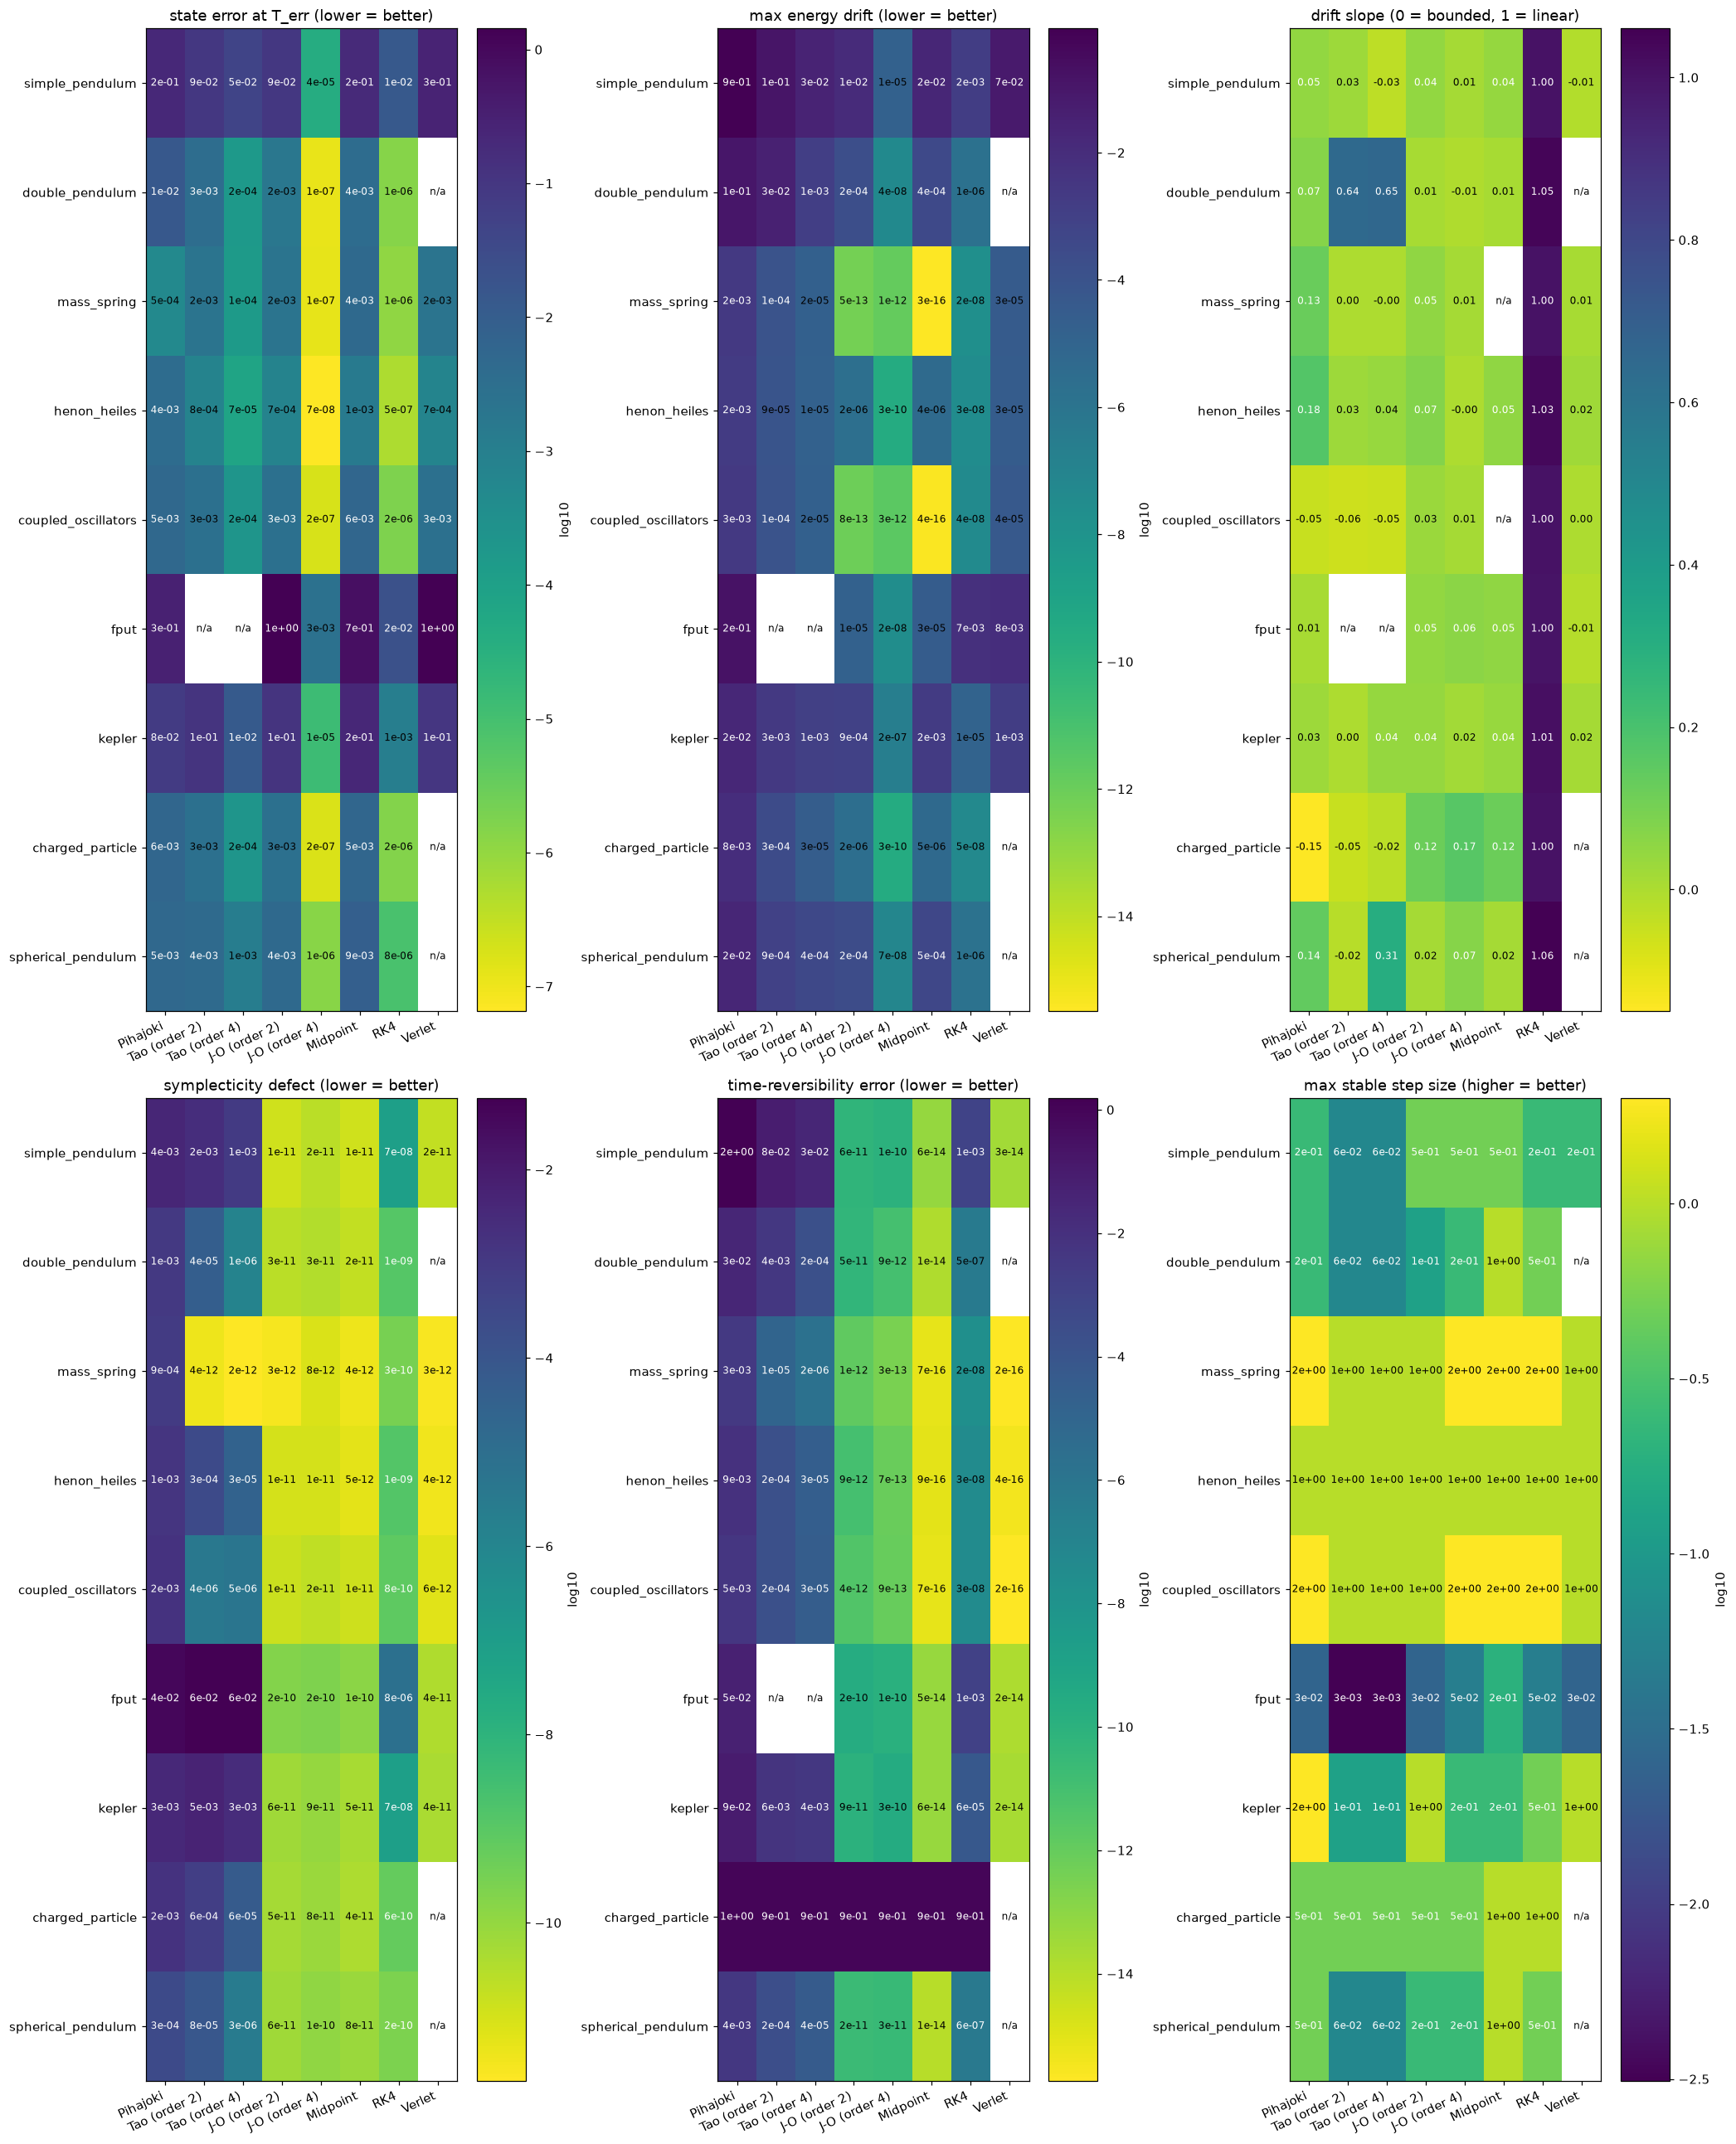

In [10]:
SYS_OK = list(TRUE)
LAB_OK = [l for l in ALL_LABELS if l in set(df_true["method"])]


def piv(df, col, rows="system", cols="method", ridx=None, rcol=None):
    p = df.pivot(index=rows, columns=cols, values=col)
    return p.reindex(index=ridx if ridx is not None else SYS_OK,
                     columns=rcol if rcol is not None else LAB_OK)


panels = [
    ("err_Terr", "state error at T_err (lower = better)", True, True),
    ("drift_max", "max energy drift (lower = better)", True, True),
    ("drift_slope", "drift slope (0 = bounded, 1 = linear)", False, True),
    ("symp_defect", "symplecticity defect (lower = better)", True, True),
    ("rev_err", "time-reversibility error (lower = better)", True, True),
    ("h_max_stable", "max stable step size (higher = better)", True, False),
]
fig, axes = plt.subplots(2, 3, figsize=(19, 2.4 * max(len(SYS_OK), 2) + 2))
for ax, (col, title, log, lower) in zip(axes.ravel(), panels):
    heat(ax, piv(df_true, col), title, log=log, lower_is_better=lower)
plt.tight_layout()
save(fig, "true_heatmaps")
plt.show()

In [11]:
# Mean rank over systems (1 = best) on accuracy, energy drift and symplecticity
rank_cols = ["err_Terr", "drift_max", "symp_defect"]
R = {c: piv(df_true, c).rank(axis=1) for c in rank_cols}
R_mean = sum(R.values()) / len(R)
print("Mean rank per system (1 = best):")
display(R_mean.round(2))
print("\nOverall mean rank (lower is better):")
display(R_mean.mean(axis=0).sort_values().round(2).to_frame("mean rank"))

Mean rank per system (1 = best):


method,Pihajoki,Tao (order 2),Tao (order 4),J-O (order 2),J-O (order 4),Midpoint,RK4,Verlet
system,,,,,,,,
simple_pendulum,7.67,6,4.67,3,2,4,3,5.67
double_pendulum,7,5.67,4.33,3,1.67,3.67,2.67,NaN
mass_spring,6.67,5.33,3,3.67,3.33,4.67,4.33,5
henon_heiles,8,6.67,4.67,4,1.67,4.33,3,3.67
coupled_oscillators,7.67,5.67,5,3.33,2.67,3.67,3.67,4.33
fput,5,7.67,7.33,3.67,2,3,3.67,3.67
kepler,6.33,7,4.33,4.33,2,5.33,3,3.67
charged_particle,7,5.67,4.33,3,1.67,3.67,2.67,NaN
spherical_pendulum,6.67,5.33,4,3,1.67,4.67,2.67,NaN



Overall mean rank (lower is better):


,mean rank
method,
J-O (order 4),2.07
RK4,3.19
J-O (order 2),3.44
Midpoint,4.11
Verlet,4.33
Tao (order 4),4.63
Tao (order 2),6.11
Pihajoki,6.89


## Energy drift and state error over time

Lines are medians over the test trajectories, shaded bands are inter-quartile ranges. The dotted vertical line marks `T_err` for chaotic systems, beyond which the state error mostly measures sensitivity to initial conditions rather than integrator quality.

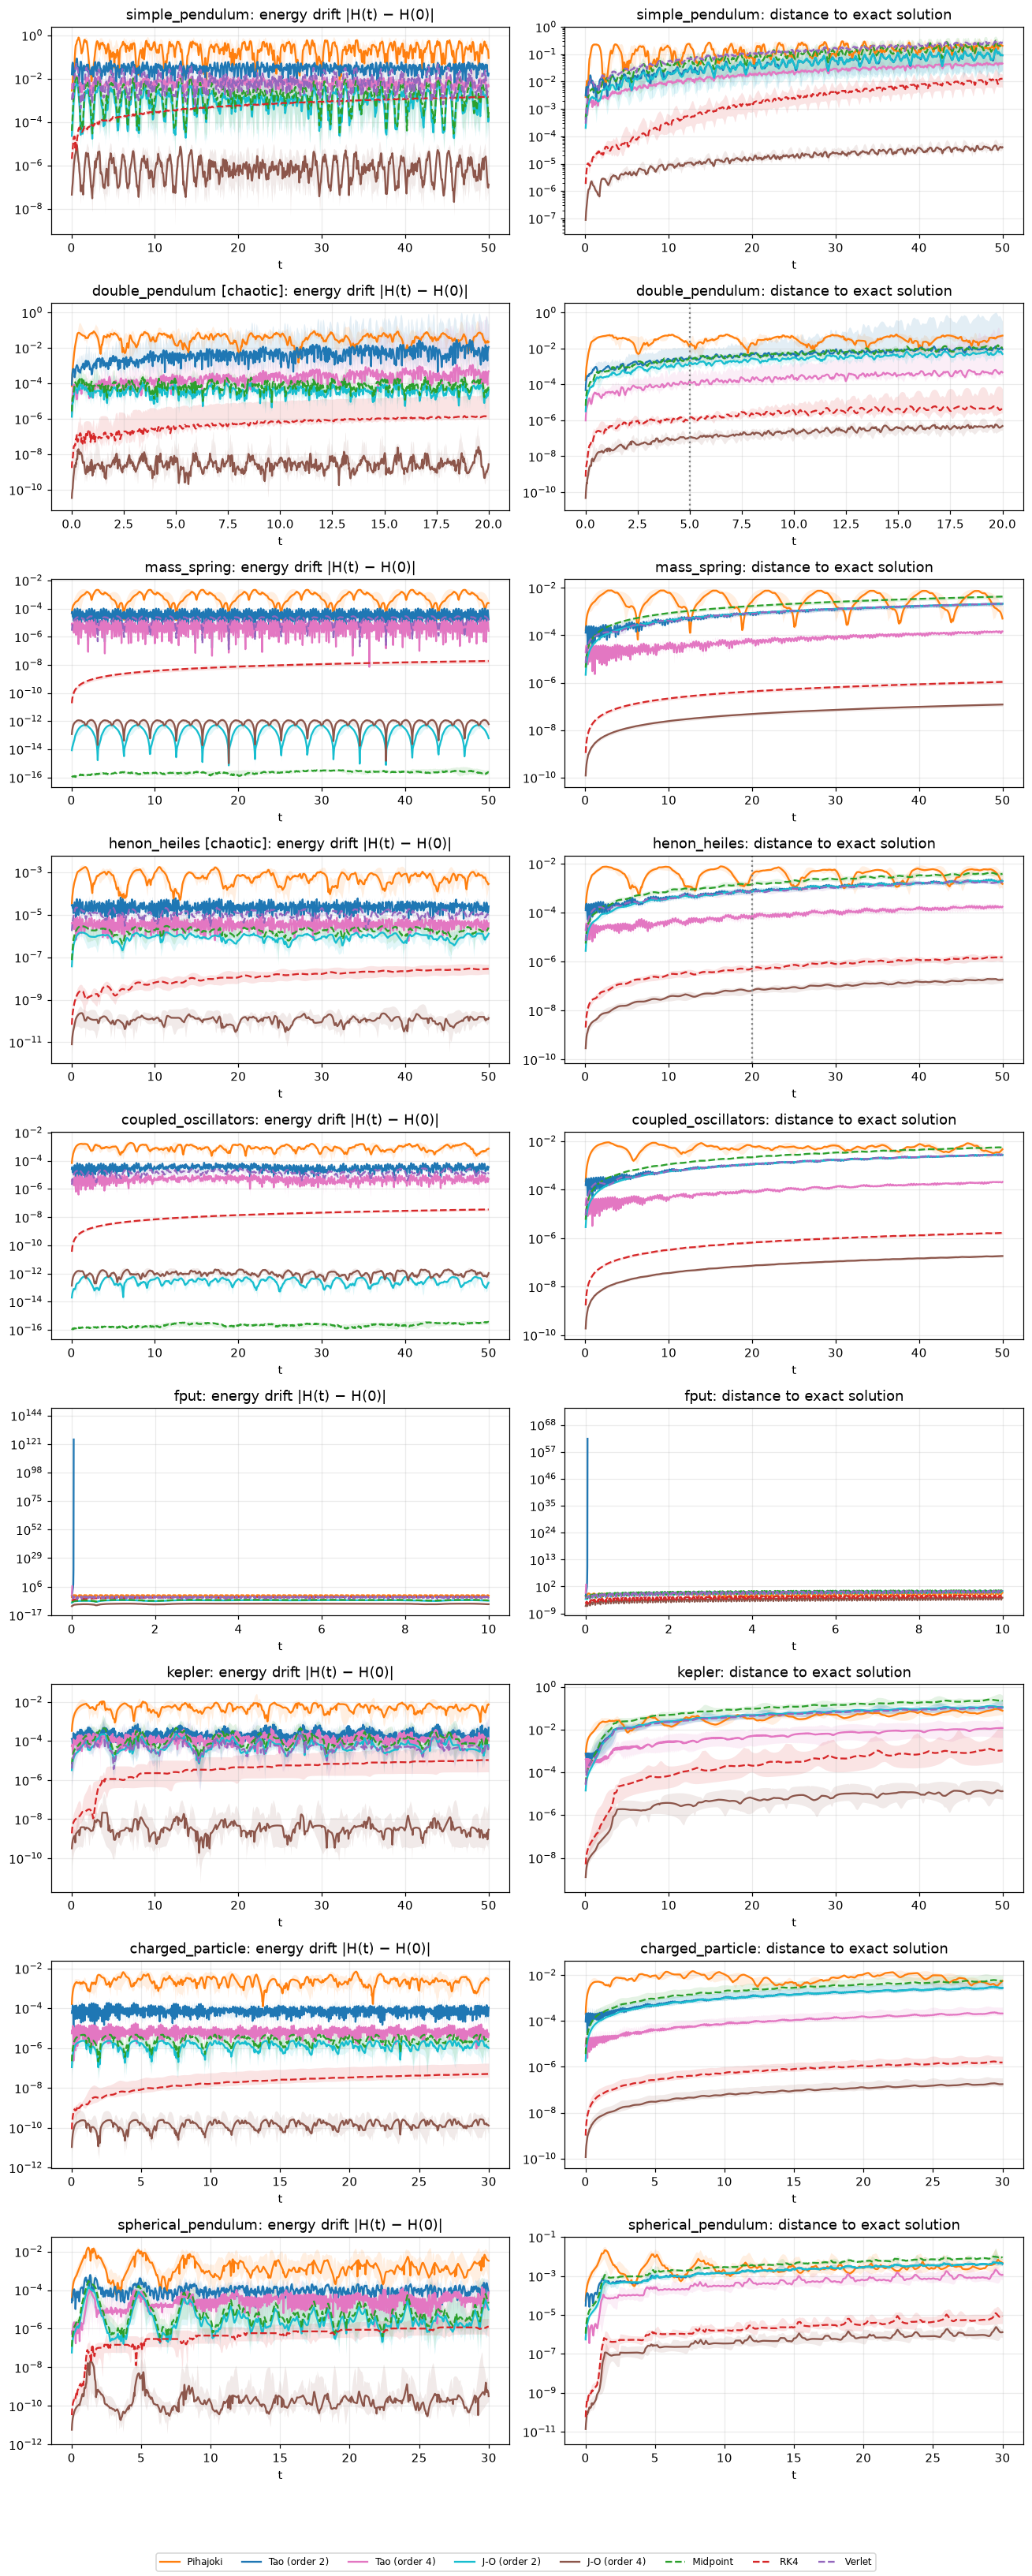

In [12]:
fig, axes = plt.subplots(len(SYS_OK), 2, figsize=(12, 3.3 * len(SYS_OK)), squeeze=False)
for row, key in enumerate(SYS_OK):
    res = TRUE[key]
    t, cfg = res["t"], res["cfg"]
    tag = " [chaotic]" if cfg["chaotic"] else ""
    for label, r in res["runs"].items():
        band(axes[row, 0], t, r["drift"], label)
        band(axes[row, 1], t, r["err"], label)
    axes[row, 0].set_title(f"{key}{tag}: energy drift |H(t) − H(0)|")
    axes[row, 1].set_title(f"{key}: distance to exact solution")
    if cfg["chaotic"]:
        axes[row, 1].axvline(cfg["T_err"], color="gray", ls=":")
    for ax in axes[row]:
        ax.set_xlabel("t")
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=len(l_))
plt.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "true_timeseries")
plt.show()

## Convergence, accuracy-vs-cost and wall-clock

Only stable sweep points are drawn. Dotted gray lines show orders 2 and 4.

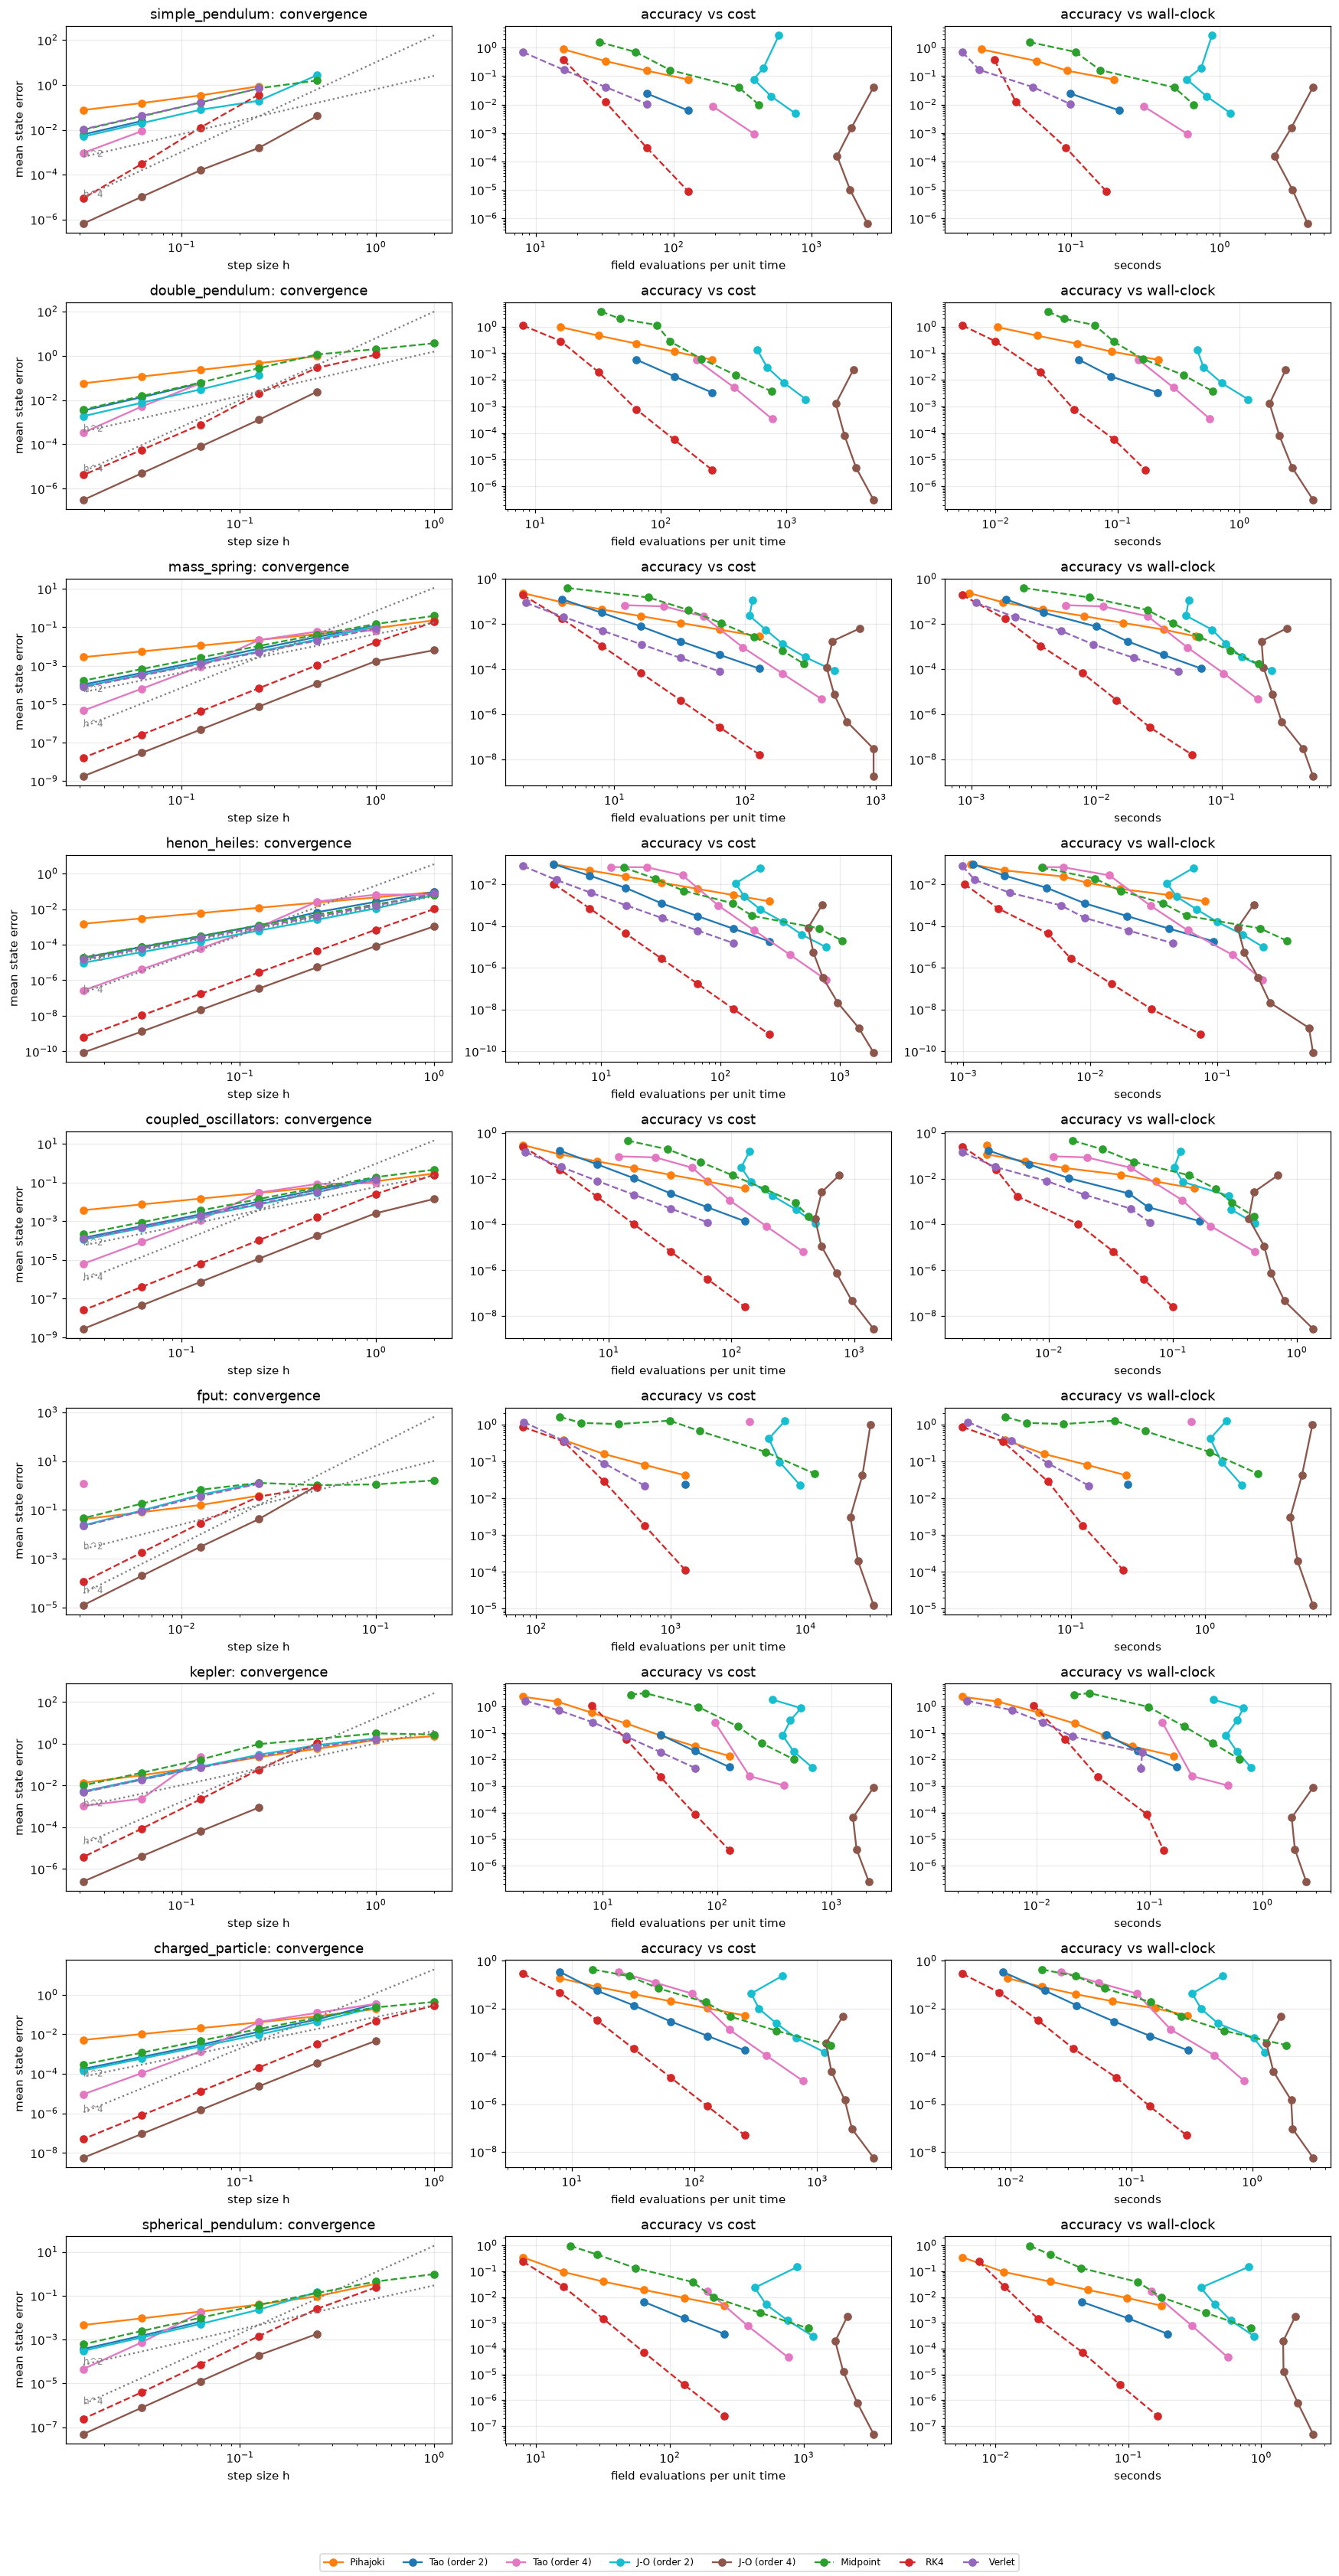

In [13]:
fig, axes = plt.subplots(len(SYS_OK), 3, figsize=(16, 3.4 * len(SYS_OK)), squeeze=False)
for row, key in enumerate(SYS_OK):
    sweep = TRUE[key]["sweep"]
    for label, pts in sweep.items():
        P = np.array([(p["h"], p["err"], p["evals"], p["seconds"]) for p in pts
                      if p["stable"] and np.isfinite(p["err"]) and p["err"] > 0])
        if len(P) == 0:
            continue
        h, e, w, s = P.T
        st = {k: v for k, v in sty(label).items() if k != "lw"}
        axes[row, 0].loglog(h, e, marker="o", label=label, **st)
        axes[row, 1].loglog(w, e, marker="o", label=label, **st)
        axes[row, 2].loglog(s, e, marker="o", label=label, **st)
    hh = np.array(sorted({p["h"] for pts in sweep.values() for p in pts}))[::-1]
    allE = [p["err"] for pts in sweep.values() for p in pts
            if p["stable"] and np.isfinite(p["err"]) and p["err"] > 0]
    if allE:
        e0, h0 = np.median(allE), hh[len(hh) // 2]
        for order in (2, 4):
            axes[row, 0].loglog(hh, e0 * (hh / h0) ** order, ":", color="gray")
            axes[row, 0].text(hh[-1], e0 * (hh[-1] / h0) ** order, f"h^{order}",
                              color="gray", fontsize=8)
    axes[row, 0].set_title(f"{key}: convergence")
    axes[row, 0].set_xlabel("step size h")
    axes[row, 0].set_ylabel("mean state error")
    axes[row, 1].set_title("accuracy vs cost")
    axes[row, 1].set_xlabel("field evaluations per unit time")
    axes[row, 2].set_title("accuracy vs wall-clock")
    axes[row, 2].set_xlabel("seconds")
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=len(l_))
plt.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "true_convergence")
plt.show()

## Tao restraint ω on every system

ω is expressed relative to the system frequency `omega0` (see the configuration cell), so the sweep is comparable between systems.

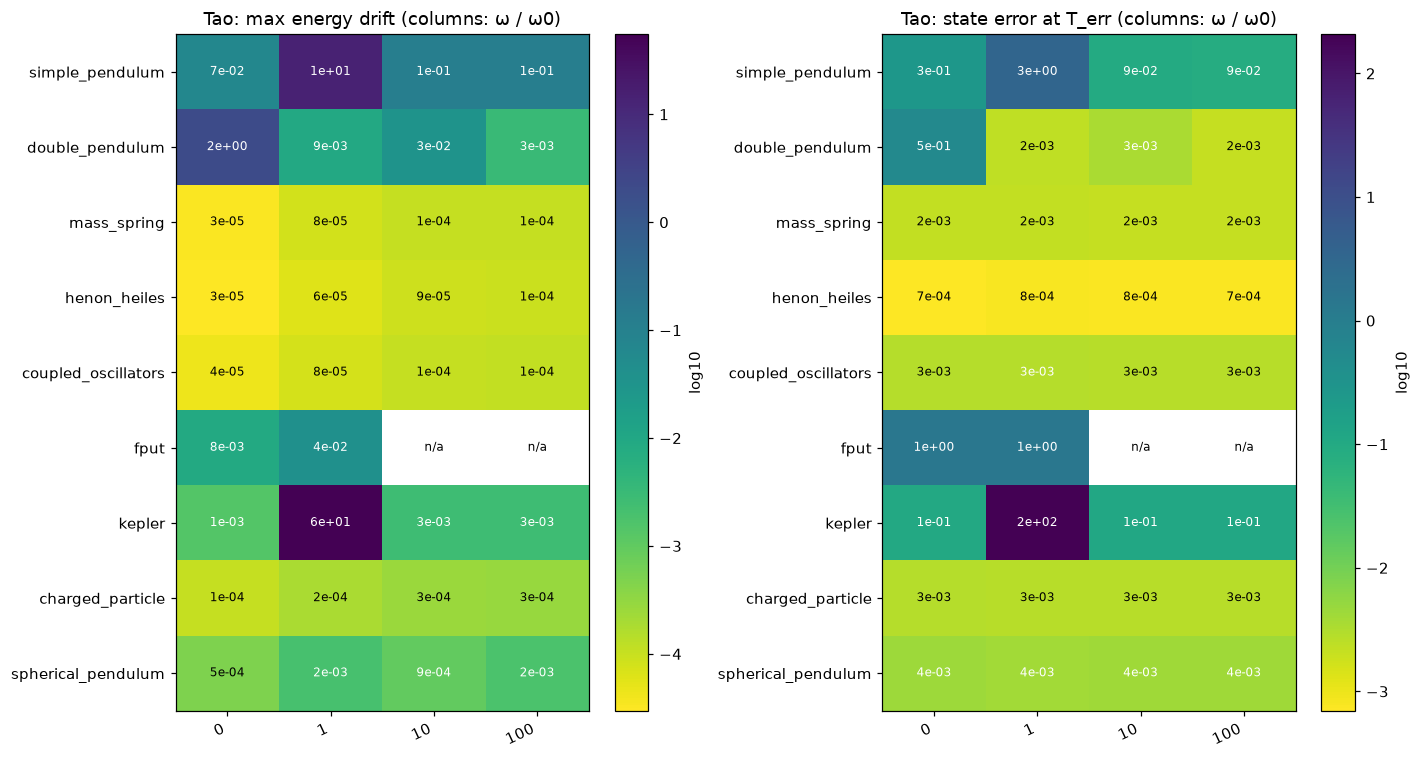

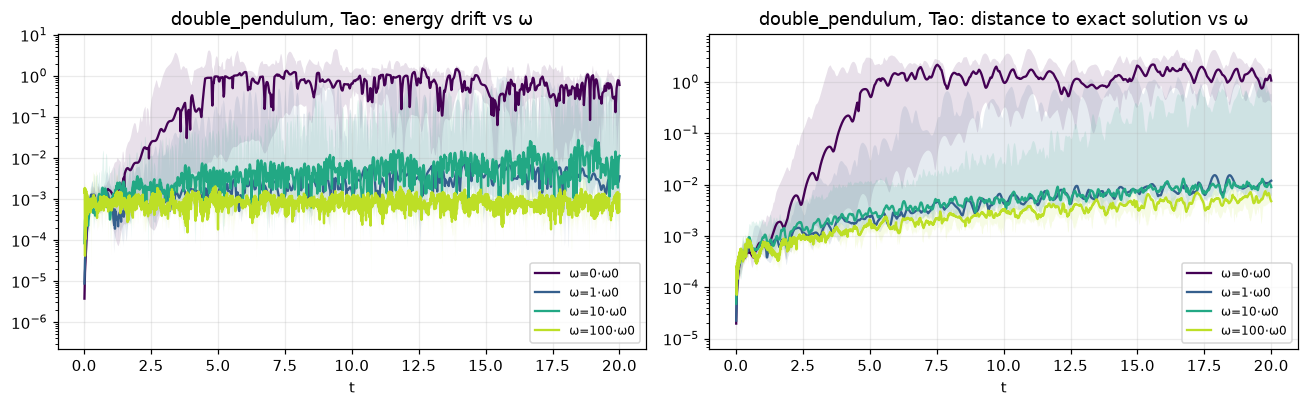

In [14]:
def omega_sweep(key):
    res = TRUE[key]
    system, d, cfg = res["system"], res["d"], res["cfg"]
    out = {}
    for rel in OMEGAS_REL:
        r = run_method("tao", rel * cfg["omega0"], res["Y0"], d, cfg["T"], cfg["steps"],
                       res["f_flat"], system.dynamics)
        if r["traj"] is not None:
            out[rel] = dict(err=state_error(r["traj"], res["ref"]),
                            drift=energy_drift(res["H"], r["traj"]))
    return out


OM = {key: omega_sweep(key) for key in TRUE}
cols = [f"{w:g}" for w in OMEGAS_REL]
P_drift = pd.DataFrame(
    {f"{w:g}": {k: max_over_time(OM[k][w]["drift"]) if w in OM[k] else np.nan for k in OM}
     for w in OMEGAS_REL})
P_err = pd.DataFrame(
    {f"{w:g}": {k: err_at(OM[k][w]["err"], TRUE[k]["i_err"]) if w in OM[k] else np.nan
                for k in OM} for w in OMEGAS_REL})
fig, axes = plt.subplots(1, 2, figsize=(13, 1.6 + 0.6 * len(OM)))
heat(axes[0], P_drift, "Tao: max energy drift (columns: ω / ω0)")
heat(axes[1], P_err, "Tao: state error at T_err (columns: ω / ω0)")
plt.tight_layout()
save(fig, "tao_omega_heatmaps")
plt.show()

# detail on one system
fs = FOCUS_SYSTEM if FOCUS_SYSTEM in OM else next(iter(OM))
t = TRUE[fs]["t"]
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(OM[fs])))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for c, (w, r) in zip(cmap, OM[fs].items()):
    band(axes[0], t, r["drift"], f"ω={w:g}·ω0", color=c, ls="-")
    band(axes[1], t, r["err"], f"ω={w:g}·ω0", color=c, ls="-")
axes[0].set_title(f"{fs}, Tao: energy drift vs ω")
axes[1].set_title(f"{fs}, Tao: distance to exact solution vs ω")
for ax in axes:
    ax.set_xlabel("t")
    ax.legend()
plt.tight_layout()
save(fig, "tao_omega_focus")
plt.show()

## Poincaré sections (Hénon–Heiles)

Section q₁ = 0, p₁ > 0, drawn in the (q₂, p₂) plane. A good integrator should keep invariant curves (regular orbits) or an unbroken chaotic sea. Systematic spiralling, shrinking or fattening of the curves indicates energy drift. Requires Hénon–Heiles in `SYSTEMS`; assumes the state layout `[q1, q2, p1, p2]`.

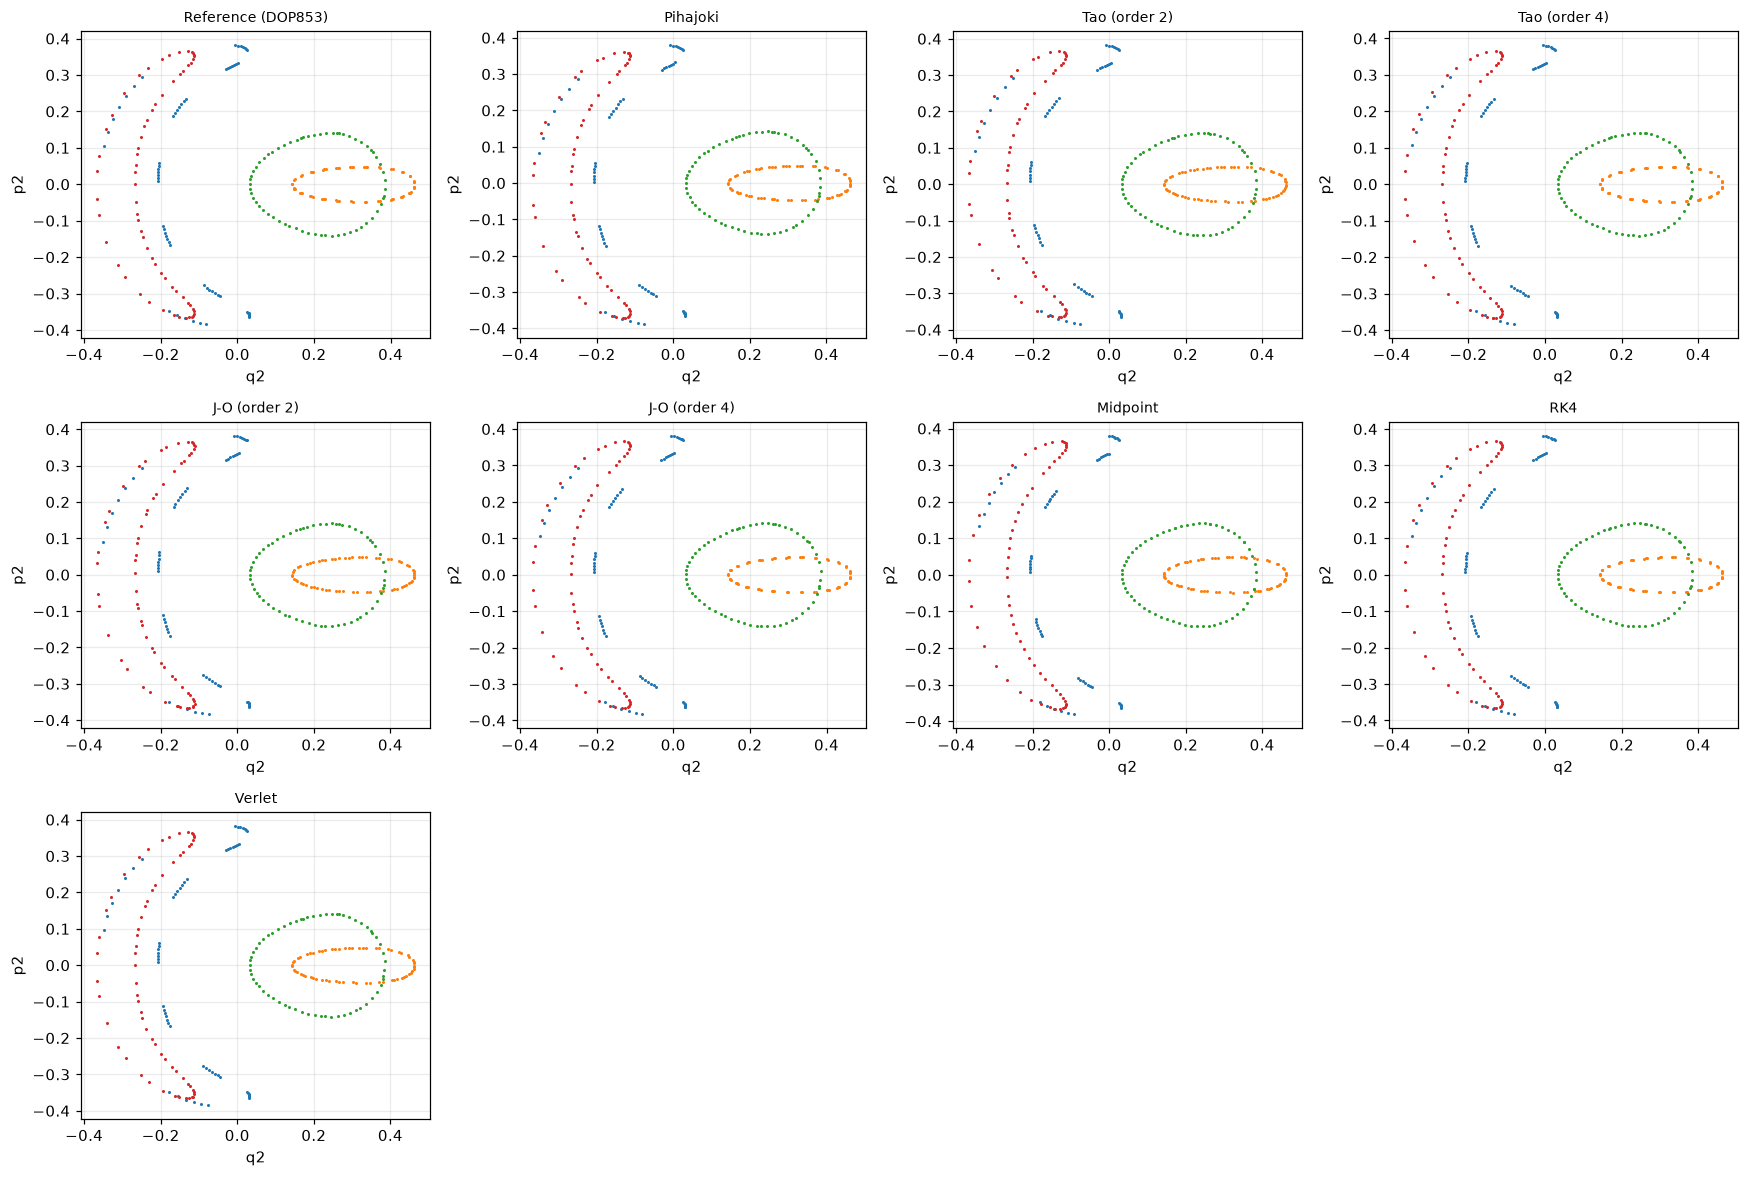

In [15]:
def poincare_section(traj, iq=0, ip=2, jq=1, jp=3):
    # crossings of q1 = 0 with p1 > 0, linearly interpolated -> (q2, p2)
    q = traj[:, iq]
    s = np.where((q[:-1] < 0) & (q[1:] >= 0))[0]
    s = s[traj[s, ip] > 0]
    if len(s) == 0:
        return np.array([]), np.array([])
    a = (-q[s] / (q[s + 1] - q[s]))[:, None]
    pts = traj[s] + a * (traj[s + 1] - traj[s])
    return pts[:, jq], pts[:, jp]


if "henon_heiles" in TRUE:
    system = SYSTEM_BUILDERS["henon_heiles"]()
    d = system.state_dim // 2
    Yp = np.asarray(system.generate_initial_conditions(POINCARE_N, seed=7), float)
    fp = oracle_field_batched(system, POINCARE_N, d)
    runs_p = {"Reference (DOP853)": dict(
        traj=solve_reference(fp, Yp, d, POINCARE_T, POINCARE_STEPS, 1e-9, 1e-9))}
    runs_p.update(run_all(methods_for("henon_heiles"), Yp, d, POINCARE_T, POINCARE_STEPS,
                          fp, system.dynamics))
    runs_p = {k: v for k, v in runs_p.items() if v["traj"] is not None}
    ncol = 4
    nrow = int(np.ceil(len(runs_p) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.6 * nrow), squeeze=False)
    for ax, (label, r) in zip(axes.ravel(), runs_p.items()):
        for k in range(POINCARE_N):
            x, y = poincare_section(r["traj"][k])
            ax.plot(x, y, ".", ms=2, color=f"C{k}")
        ax.set_title(label, fontsize=9)
        ax.set_xlabel("q2")
        ax.set_ylabel("p2")
    for ax in axes.ravel()[len(runs_p):]:
        ax.axis("off")
    plt.tight_layout()
    save(fig, "henon_heiles_poincare")
    plt.show()
else:
    print("henon_heiles not in TRUE: skipping Poincaré sections")

# Part B — integrators on learned models

For every system in `LEARNED_SYSTEMS` and every training seed, all models are trained and rolled out with every integrator. Three errors are recorded (all averaged over time, median over test trajectories):

| quantity | compares | meaning |
|---|---|---|
| `int_err` | integrator vs reference solve of the **learned** field | pure integration error |
| `model_err` | reference solve of the **learned** field vs **truth** | pure model error (independent of the integrator) |
| `truth_err` | integrator vs **truth** | what you actually get |

If `int_err` ≪ `model_err` the integrator choice is irrelevant for that model; if `int_err` ≳ `model_err` it matters. `trueH_drift` is the drift of the *true* Hamiltonian along the rollout, which is defined for every model including the non-Hamiltonian MLP.

In [16]:
import torch
from src.models.baselines import MLP, HNN, DoubleHeadHNN, CholeskyHNN
from src.models.geohnn import GeoHNN
from src.models.api import predict_derivative
from src.integrators.model_field import batched_field, model_vector_field


def build_model(name, state_dim):
    d = state_dim // 2
    return {
        "MLP": lambda: MLP(state_dim, HIDDEN),
        "HNN": lambda: HNN(state_dim, HIDDEN),
        "DoubleHeadHNN": lambda: DoubleHeadHNN(state_dim, HIDDEN),
        "CholeskyHNN": lambda: CholeskyHNN(state_dim, HIDDEN),
        "GeoHNN": lambda: GeoHNN(d),
    }[name]()


def train_model(model, X, dX, epochs, batch, lr, seed=0):
    torch.manual_seed(seed)
    X = torch.as_tensor(X, dtype=torch.float32)
    dX = torch.as_tensor(dX, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n, hist = X.shape[0], []
    model.train()
    for ep in range(epochs):
        perm, tot = torch.randperm(n), 0.0
        for i in range(0, n, batch):
            idx = perm[i : i + batch]
            loss = ((predict_derivative(model, X[idx]) - dX[idx]) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        hist.append(tot / n)
    model.eval()
    return hist


def learned_hamiltonian(model, name):
    # H_learned(X) for (M, 2d) numpy states; None for the (non-Hamiltonian) MLP
    if name == "MLP":
        return None
    dtype = next(model.parameters()).dtype

    def H(X):
        x = torch.as_tensor(np.asarray(X), dtype=dtype)
        with torch.no_grad():
            if name == "GeoHNN":
                h = model.compute_hamiltonian(
                    x[:, : model.n_dof].contiguous(), x[:, model.n_dof :].contiguous()
                )[0]
            else:
                h = model(x)
        return h.reshape(-1).double().numpy()

    return H

In [17]:
def run_learned(key, train_seed, n_train=None, noise=0.0, models=None, tag="main"):
    # trains `models` on `key`, rolls out with all integrators, returns (rows, context)
    n_train = N_TRAIN if n_train is None else n_train
    models = MODELS if models is None else models
    cfg = SYSTEM_CFG[key]
    system = SYSTEM_BUILDERS[key]()
    D = system.state_dim
    d = D // 2
    T, n = cfg["roll_T"], cfg["roll_steps"]
    Y0 = np.asarray(system.generate_initial_conditions(N_TEST, seed=SEED_TEST), float)
    f_true = oracle_field_batched(system, N_TEST, d)
    ref_truth = solve_reference(f_true, Y0, d, T, n, 1e-10, 1e-10)
    H_true = true_H_fn(system)

    data = generate_dataset(system, n_train, TSPAN_TRAIN, STEPS_TRAIN, seed=train_seed, system_key=key)
    X, dX = data["X"].reshape(-1, D), data["dX"].reshape(-1, D)
    if noise > 0:  # measurement noise on the input states, relative to each dimension's std
        rng = np.random.default_rng(train_seed)
        X = X + noise * X.std(0) * rng.standard_normal(X.shape)

    methods = methods_for(key, verlet=False)
    ctx = dict(system=system, d=d, T=T, n=n, Y0=Y0, ref_truth=ref_truth,
               models={}, hist={}, runs={}, ref_model={}, H_learned={})
    rows = []
    for name in models:
        t0 = time.perf_counter()
        try:
            m = build_model(name, D)
            ctx["hist"][name] = train_model(m, X, dX, EPOCHS, BATCH, LR, seed=train_seed)
        except Exception as e:
            print(f"   {key}/{name}: training FAILED: {type(e).__name__}: {e}")
            continue
        f_b, f_s = batched_field(m, N_TEST, d), model_vector_field(m)
        try:
            ref_m = solve_reference(f_b, Y0, d, T, n, REF_RTOL, REF_ATOL)
        except Exception as e:
            print(f"   {key}/{name}: reference solve of the learned field failed ({e}); skipping")
            continue
        H_l = learned_hamiltonian(m, name)
        runs = run_all(methods, Y0, d, T, n, f_b, f_s)
        model_err = mean_over_time(state_error(ref_m, ref_truth))
        ctx["models"][name], ctx["ref_model"][name] = m, ref_m
        ctx["H_learned"][name], ctx["runs"][name] = H_l, runs
        for label, r in runs.items():
            if r["traj"] is None:
                continue
            rows.append(dict(
                tag=tag, system=key, model=name, train_seed=train_seed,
                n_train=n_train, noise=noise, method=label,
                int_err=mean_over_time(state_error(r["traj"], ref_m)),
                truth_err=mean_over_time(state_error(r["traj"], ref_truth)),
                model_err=model_err,
                trueH_drift=max_over_time(energy_drift(H_true, r["traj"])),
                learnedH_drift=(max_over_time(energy_drift(H_l, r["traj"]))
                                if H_l is not None else np.nan),
            ))
        print(f"   {key:18s} seed {train_seed} {name:14s} "
              f"loss {ctx['hist'][name][-1]:.2e}  ({time.perf_counter() - t0:5.1f}s)")
    return rows, ctx

In [18]:
LEARNED, LEARNED_ROWS = {}, []
if RUN_LEARNED:
    for key in LEARNED_SYSTEMS:
        for s in TRAIN_SEEDS:
            rows, ctx = run_learned(key, s)
            LEARNED_ROWS += rows
            LEARNED[(key, s)] = ctx
    df_learned = pd.DataFrame(LEARNED_ROWS)
    df_learned.to_csv(OUT / "learned_all_rows.csv", index=False)
    METRICS = ["int_err", "truth_err", "model_err", "trueH_drift", "learnedH_drift"]
    agg = (df_learned.replace([np.inf, -np.inf], np.nan)
           .groupby(["system", "model", "method"])[METRICS].median().reset_index())
    agg.to_csv(OUT / "learned_summary.csv", index=False)
    display(agg.round(4).set_index(["system", "model", "method"]))

   double_pendulum    seed 42 HNN            loss 4.64e-03  ( 57.6s)
   double_pendulum    seed 42 GeoHNN         loss 5.45e-02  (197.9s)
   double_pendulum    seed 43 HNN            loss 6.09e-03  ( 47.3s)
   double_pendulum    seed 43 GeoHNN         loss 1.89e-02  (243.3s)
   henon_heiles       seed 42 HNN            loss 3.02e-05  ( 44.6s)
   henon_heiles       seed 42 GeoHNN         loss 4.30e-05  (228.6s)
   henon_heiles       seed 43 HNN            loss 3.49e-05  ( 51.8s)
   henon_heiles       seed 43 GeoHNN         loss 1.76e-05  (278.6s)
   spherical_pendulum seed 42 HNN            loss 7.48e-03  (130.7s)
   spherical_pendulum seed 42 GeoHNN         loss 7.81e-02  (580.5s)
   spherical_pendulum seed 43 HNN            loss 4.23e-03  (112.7s)
   spherical_pendulum seed 43 GeoHNN         loss 1.20e-01  (605.1s)


int_err  truth_err  model_err  trueH_drift  learnedH_drift
system             model  method                                                                   
double_pendulum    GeoHNN J-O (order 2)   0.0032      0.235      0.235        0.201          0.0007
                          J-O (order 4)        0      0.235      0.235        0.201               0
                          Midpoint        0.0065      0.237      0.235        0.201          0.0013
                          Pihajoki        0.0733      0.262      0.235        0.331           0.206
                          RK4                  0      0.235      0.235        0.201               0
                          Tao (order 2)   0.0051      0.235      0.235        0.201          0.0269
                          Tao (order 4)   0.0008      0.235      0.235        0.201          0.0043
                   HNN    J-O (order 2)   0.0028      0.128      0.128        0.104          0.0007
                          J-O (order 4)        0      0.128      0.128        0.104               0
                          Midpoint        0.0056      0.129      0.128        0.105          0.0015
                          Pihajoki        0.0718      0.166      0.128        0.269           0.211
                          RK4                  0      0.128      0.128        0.104               0
                          Tao (order 2)   0.0053      0.129      0.128        0.116          0.0332
                          Tao (order 4)   0.0009      0.128      0.128        0.104           0.006
henon_heiles       GeoHNN J-O (order 2)   0.0003     0.0281     0.0282       0.0018               0
                          J-O (order 4)        0     0.0282     0.0282       0.0018               0
                          Midpoint        0.0006     0.0284     0.0282       0.0018               0
                          Pihajoki        0.0041     0.0296     0.0282       0.0028           0.002
                          RK4                  0     0.0282     0.0282       0.0018               0
                          Tao (order 2)   0.0004     0.0281     0.0282       0.0019          0.0001
                          Tao (order 4)        0     0.0282     0.0282       0.0018               0
                   HNN    J-O (order 2)   0.0003     0.0332      0.033        0.004               0
                          J-O (order 4)        0      0.033      0.033        0.004               0
                          Midpoint        0.0006     0.0326      0.033        0.004               0
                          Pihajoki         0.004     0.0321      0.033        0.005           0.002
                          RK4                  0      0.033      0.033        0.004               0
                          Tao (order 2)   0.0003     0.0332      0.033       0.0039          0.0001
                          Tao (order 4)        0      0.033      0.033        0.004               0
spherical_pendulum GeoHNN J-O (order 2)   0.0018       1.27       1.27         1.05          0.0003
                          J-O (order 4)        0       1.27       1.27         1.05               0
                          Midpoint        0.0036       1.27       1.27         1.05          0.0007
                          Pihajoki        0.0092       1.27       1.27         1.05          0.0254
                          RK4                  0       1.27       1.27         1.05               0
                          Tao (order 2)   0.0019       1.27       1.27         1.05          0.0013
                          Tao (order 4)   0.0003       1.27       1.27         1.05          0.0004
                   HNN    J-O (order 2)   0.0023      0.404      0.404        0.328          0.0005
                          J-O (order 4)        0      0.404      0.404        0.327               0
                          Midpoint        0.0046      0.404      0.404        0.327           0.001
                          Pihajoki       

## Heatmaps: model × integrator, one row per system

Median over training seeds.

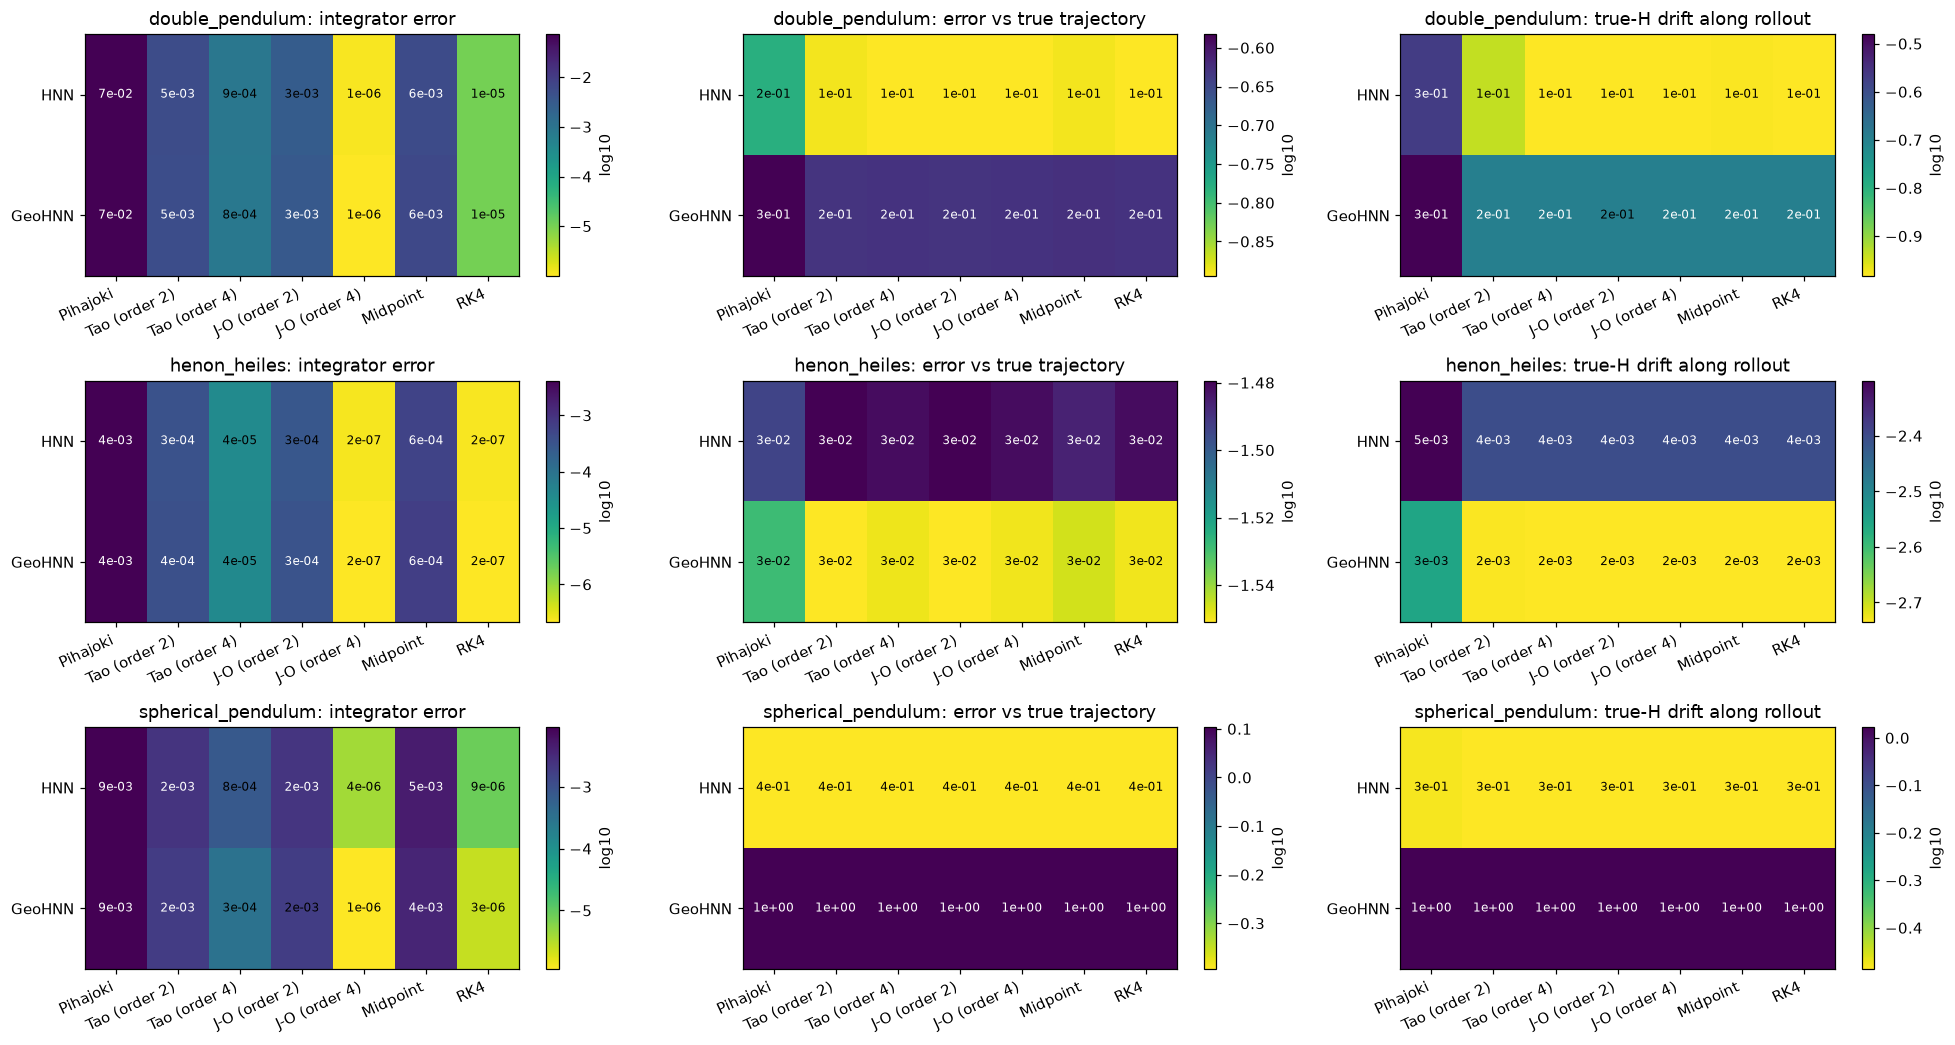

In [19]:
if RUN_LEARNED:
    sys_l = [k for k in LEARNED_SYSTEMS if k in set(agg["system"])]
    mod_l = [m for m in MODELS if m in set(agg["model"])]
    lab_l = list(methods_for(sys_l[0], verlet=False))
    fig, axes = plt.subplots(len(sys_l), 3, figsize=(18, 3.2 * len(sys_l)), squeeze=False)
    for row, key in enumerate(sys_l):
        sub = agg[agg["system"] == key]
        for ax, (col, title) in zip(axes[row], [
            ("int_err", "integrator error"),
            ("truth_err", "error vs true trajectory"),
            ("trueH_drift", "true-H drift along rollout"),
        ]):
            heat(ax, piv(sub, col, rows="model", cols="method", ridx=mod_l, rcol=lab_l),
                 f"{key}: {title}")
    plt.tight_layout()
    save(fig, "learned_heatmaps")
    plt.show()

## Error decomposition: does the integrator matter?

Black bars: model error of each model. Coloured dots: integrator error of each method. Wherever the dots reach or exceed the bar, the integrator is a limiting factor; where they sit far below, a better integrator would not help.

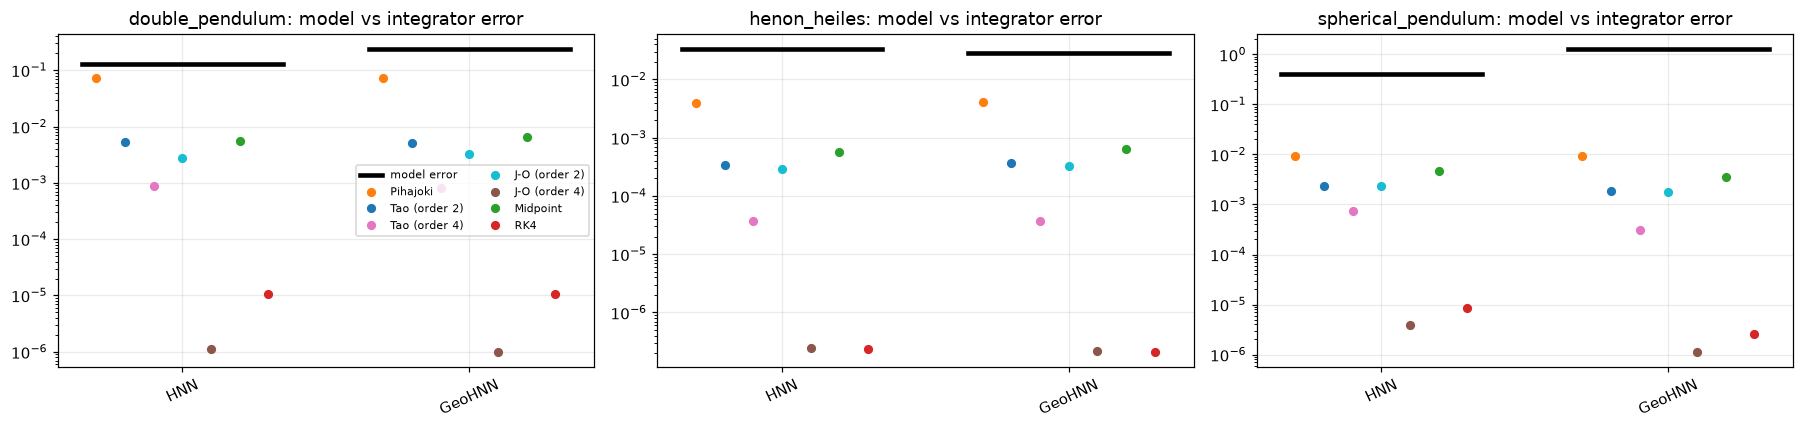

max_int_over_model > 1  =>  the integrator error exceeds the model error for at least one method


model_err    best_method  best_truth_err   worst_method  worst_truth_err  worst_over_best  max_int_over_model
system             model                                                                                                                
double_pendulum    GeoHNN      0.235  Tao (order 2)           0.235       Pihajoki            0.262             1.11               0.311
                   HNN         0.128  J-O (order 2)           0.128       Pihajoki            0.166              1.3               0.562
henon_heiles       GeoHNN     0.0282  J-O (order 2)          0.0281       Pihajoki           0.0296             1.05               0.146
                   HNN         0.033       Pihajoki          0.0321  J-O (order 2)           0.0332             1.03                0.12
spherical_pendulum GeoHNN       1.27       Pihajoki            1.27  J-O (order 2)             1.27                1              0.0073
                   HNN         0.404  Tao (order 2)           0.404       Pihajoki            0.405                1              0.0226

In [20]:
if RUN_LEARNED:
    fig, axes = plt.subplots(1, len(sys_l), figsize=(5.5 * len(sys_l), 4), squeeze=False)
    for ax, key in zip(axes[0], sys_l):
        sub = agg[agg["system"] == key]
        for i, m in enumerate(mod_l):
            g = sub[sub["model"] == m]
            if g.empty:
                continue
            ax.plot([i - 0.35, i + 0.35], [g["model_err"].iloc[0]] * 2, color="k", lw=3,
                    label="model error" if i == 0 else None)
            for j, lab in enumerate(lab_l):
                v = g.loc[g["method"] == lab, "int_err"]
                if len(v) and np.isfinite(v.iloc[0]):
                    ax.plot(i - 0.3 + 0.6 * j / max(len(lab_l) - 1, 1), v.iloc[0], "o",
                            color=COLORS.get(lab), ms=5, label=lab if i == 0 else None)
        ax.set_yscale("log")
        ax.set_xticks(range(len(mod_l)), mod_l, rotation=25)
        ax.set_title(f"{key}: model vs integrator error")
    axes[0, 0].legend(ncol=2, fontsize=7)
    plt.tight_layout()
    save(fig, "learned_decomposition")
    plt.show()

    rows = []
    for (s, m), g in agg.groupby(["system", "model"]):
        g = g.replace([np.inf, -np.inf], np.nan).dropna(subset=["truth_err"])
        if g.empty:
            continue
        b, w = g.loc[g["truth_err"].idxmin()], g.loc[g["truth_err"].idxmax()]
        rows.append(dict(
            system=s, model=m, model_err=g["model_err"].iloc[0],
            best_method=b["method"], best_truth_err=b["truth_err"],
            worst_method=w["method"], worst_truth_err=w["truth_err"],
            worst_over_best=w["truth_err"] / b["truth_err"],
            max_int_over_model=g["int_err"].max() / g["model_err"].iloc[0],
        ))
    df_dec = pd.DataFrame(rows)
    df_dec.to_csv(OUT / "learned_decomposition.csv", index=False)
    print("max_int_over_model > 1  =>  the integrator error exceeds the model error for at least one method")
    display(df_dec.round(4).set_index(["system", "model"]))

## Zoom on one system and one model

Median and inter-quartile band over test trajectories, first training seed.

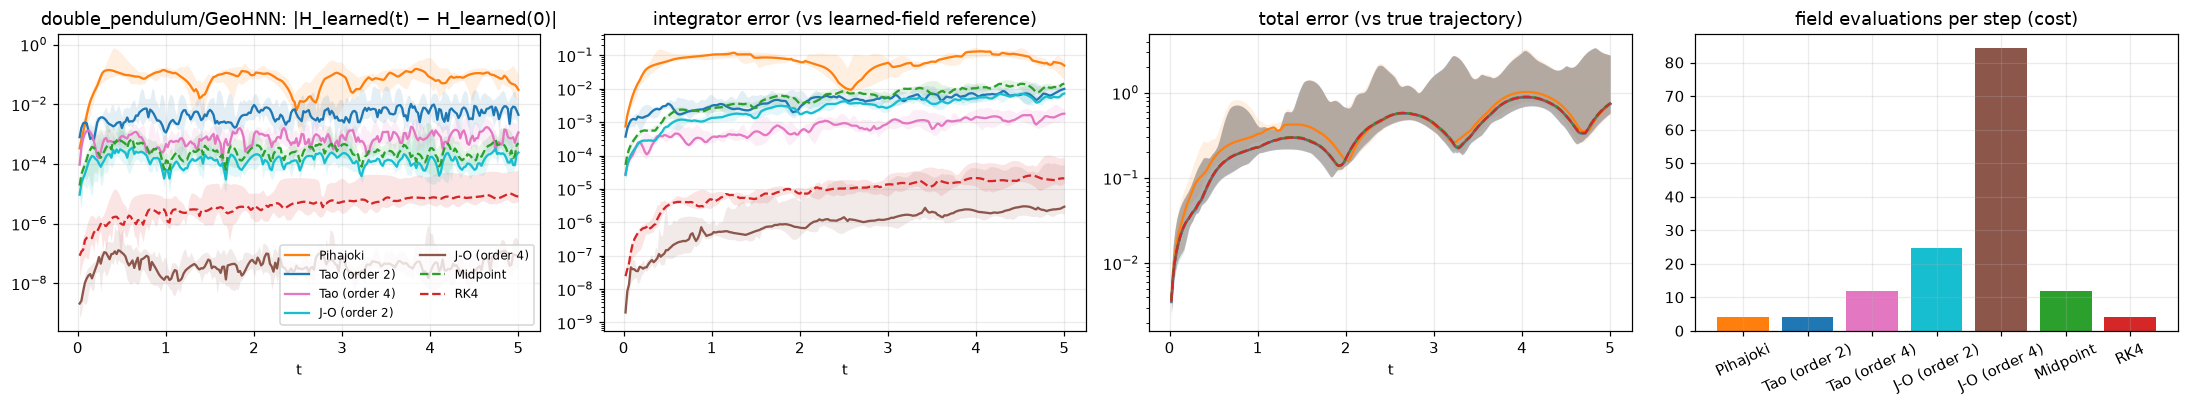

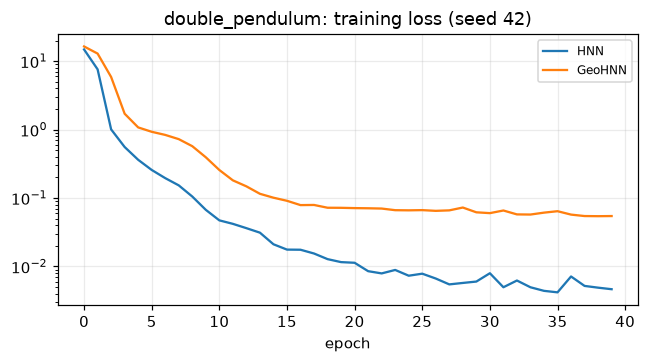

In [21]:
if RUN_LEARNED:
    fk = FOCUS_SYSTEM if FOCUS_SYSTEM in LEARNED_SYSTEMS else LEARNED_SYSTEMS[0]
    ctx = LEARNED[(fk, TRAIN_SEEDS[0])]
    fm = FOCUS_MODEL if FOCUS_MODEL in ctx["runs"] else next(iter(ctx["runs"]))
    tt = np.linspace(0, ctx["T"], ctx["n"] + 1)
    H_l = ctx["H_learned"][fm]
    fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
    for label, r in ctx["runs"][fm].items():
        if r["traj"] is None:
            continue
        if H_l is not None:
            band(axes[0], tt, energy_drift(H_l, r["traj"]), label)
        band(axes[1], tt, state_error(r["traj"], ctx["ref_model"][fm]), label)
        band(axes[2], tt, state_error(r["traj"], ctx["ref_truth"]), label)
    labels = [l for l, r in ctx["runs"][fm].items() if r["traj"] is not None]
    axes[3].bar(labels, [ctx["runs"][fm][l]["evals"] for l in labels],
                color=[COLORS[l] for l in labels])
    axes[3].tick_params(axis="x", rotation=25)
    axes[0].set_title(f"{fk}/{fm}: |H_learned(t) − H_learned(0)|")
    axes[1].set_title("integrator error (vs learned-field reference)")
    axes[2].set_title("total error (vs true trajectory)")
    axes[3].set_title("field evaluations per step (cost)")
    for ax in axes[:3]:
        ax.set_xlabel("t")
    axes[0].legend(ncol=2)
    plt.tight_layout()
    save(fig, "learned_focus")
    plt.show()

    # training curves of every model
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for name, h in ctx["hist"].items():
        ax.semilogy(h, label=name)
    ax.set_xlabel("epoch")
    ax.set_title(f"{fk}: training loss (seed {TRAIN_SEEDS[0]})")
    ax.legend()
    plt.tight_layout()
    plt.show()

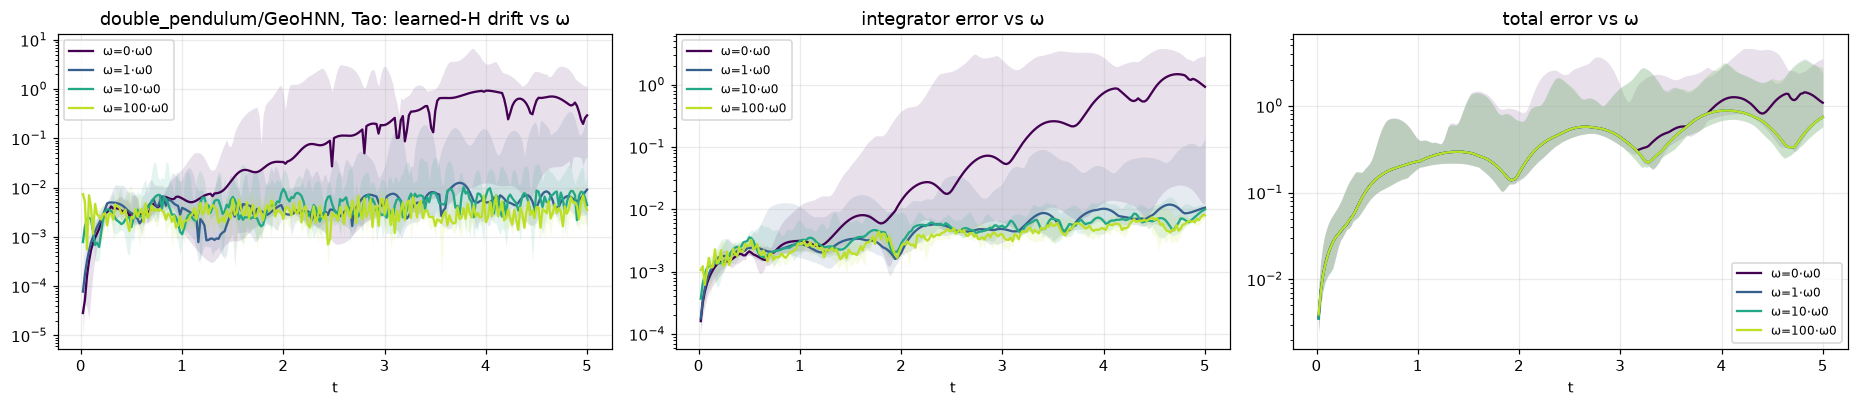

In [22]:
# Tao restraint omega on the focus model
if RUN_LEARNED:
    system, d, cfg = ctx["system"], ctx["d"], SYSTEM_CFG[fk]
    m = ctx["models"][fm]
    f_b, f_s = batched_field(m, N_TEST, d), model_vector_field(m)
    RUN_OM_M = run_all(
        {f"ω={w:g}·ω0": ("tao", w * cfg["omega0"]) for w in OMEGAS_REL},
        ctx["Y0"], d, ctx["T"], ctx["n"], f_b, f_s,
    )
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(RUN_OM_M)))
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
    for c, (label, r) in zip(cmap, RUN_OM_M.items()):
        if r["traj"] is None:
            continue
        if H_l is not None:
            band(axes[0], tt, energy_drift(H_l, r["traj"]), label, color=c, ls="-")
        band(axes[1], tt, state_error(r["traj"], ctx["ref_model"][fm]), label, color=c, ls="-")
        band(axes[2], tt, state_error(r["traj"], ctx["ref_truth"]), label, color=c, ls="-")
    axes[0].set_title(f"{fk}/{fm}, Tao: learned-H drift vs ω")
    axes[1].set_title("integrator error vs ω")
    axes[2].set_title("total error vs ω")
    for ax in axes:
        ax.set_xlabel("t")
        ax.legend()
    plt.tight_layout()
    save(fig, "learned_tao_omega")
    plt.show()

## Data ablation (focus system, focus model)

Does the ranking of the integrators change when the model is trained on less or noisier data? Compare the curves: if they are flat across configurations the integrator ordering is robust, and the printed `model_err` shows how much the model itself degrades.

   double_pendulum    seed 42 GeoHNN         loss 4.31e-01  (223.7s)
   double_pendulum    seed 42 GeoHNN         loss 5.65e+00  (2607.9s)
   double_pendulum    seed 42 GeoHNN         loss 7.03e-02  (204.4s)
   double_pendulum    seed 42 GeoHNN         loss 1.26e-01  (280.3s)
               model_err
n_train noise           
5       0           1.08
        0.05        6.82
30      0           1.74
        0.05       0.461


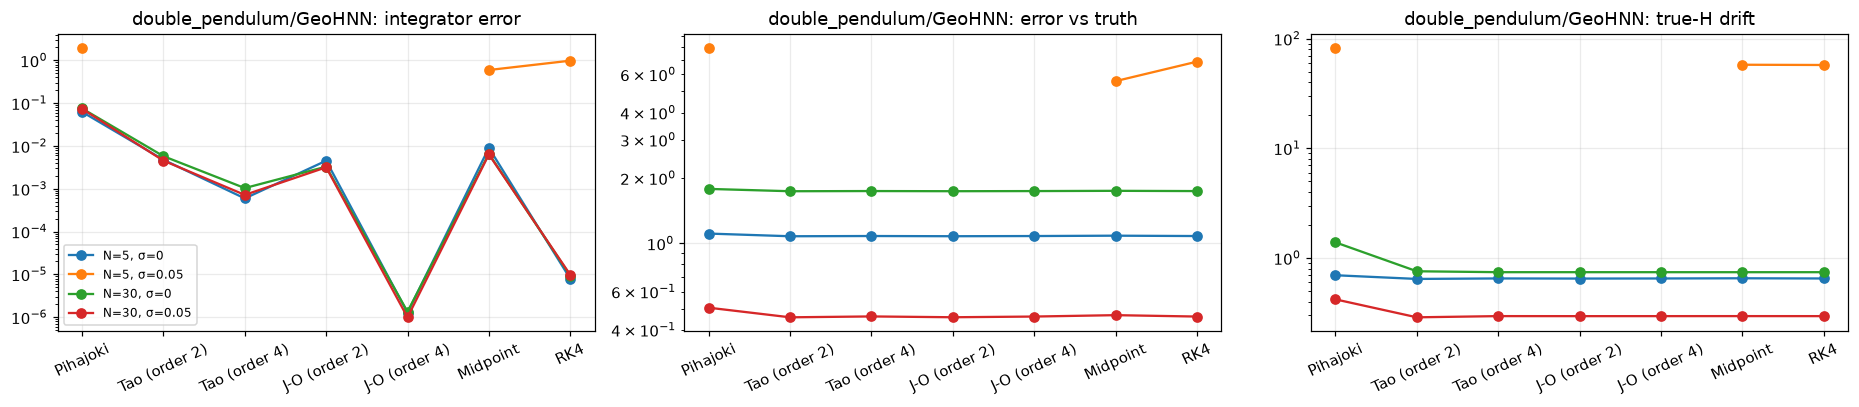

In [23]:
if RUN_LEARNED and RUN_ABLATION:
    ABL = []
    for nt in ABL_NTRAIN:
        for nz in ABL_NOISE:
            rows, _ = run_learned(fk, TRAIN_SEEDS[0], n_train=nt, noise=nz,
                                  models=[fm], tag="ablation")
            ABL += rows
    df_abl = pd.DataFrame(ABL)
    df_abl.to_csv(OUT / "learned_ablation.csv", index=False)
    print(df_abl.groupby(["n_train", "noise"])["model_err"].first().to_frame().round(5))

    labs = list(methods_for(fk, verlet=False))
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
    for (nt, nz), g in df_abl.groupby(["n_train", "noise"]):
        g = g.set_index("method").reindex(labs)
        for ax, col in zip(axes, ["int_err", "truth_err", "trueH_drift"]):
            ax.semilogy(range(len(labs)), g[col].replace([np.inf, 0], np.nan),
                        marker="o", label=f"N={nt}, σ={nz:g}")
    for ax, title in zip(axes, ["integrator error", "error vs truth", "true-H drift"]):
        ax.set_xticks(range(len(labs)), labs, rotation=25)
        ax.set_title(f"{fk}/{fm}: {title}")
    axes[0].legend()
    plt.tight_layout()
    save(fig, "learned_ablation")
    plt.show()